# Blackout Patterns: the whole project in one notebook

Mining the regimes, motifs and precursors of load shedding in Bangladesh's hourly grid data (PGCB, 2015-2026).

**How this notebook works.** Part 1 contains *every line of project code*, one cell per module. Each
code cell writes its module into `notebooks/_nb_pkg/blackout/` with `%%writefile`. Part 2 imports that
freshly written package and runs the whole pipeline: cleaning, exploratory analysis, regimes, clusters,
motifs, rules, episodes and anomalies. The same code lives in `src/blackout/` (the notebook is
generated from it by `scripts/build_notebook.py`).

**Requirements.** The raw file at `data/raw/pgcb_hourly_mendeley.csv` (not stored in git, see the README)
and the packages in `pyproject.toml` (`pip install -e ".[dev,mining,viz]"`).

**The slow step.** Comparing clustering methods with DTW takes about 15 minutes, so the notebook reuses
`docs/results/cluster_comparison.csv`. Set `RUN_CLUSTER_SEARCH = True` in the first cell of Part 2 to redo it.

Contents: [Part 1: code](#part-1) · [Part 2: run it](#part-2)

<a id="part-1"></a>
## Part 1. The code

In [1]:
import os, sys
from pathlib import Path

# Find the repository root (the folder with pyproject.toml) from wherever the notebook is run.
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.environ["BLACKOUT_ROOT"] = str(REPO)
BUILD = REPO / "notebooks" / "_nb_pkg"
(BUILD / "blackout").mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(BUILD))           # use the notebook's copy of the package, not an installed one
sys.modules.pop("blackout", None)
print("repo:", REPO)

repo: /home/user/Blackout-Patterns


In [2]:
%%writefile ../notebooks/_nb_pkg/blackout/__init__.py
"""Blackout Patterns: pattern mining on Bangladesh's PGCB hourly grid data."""

__version__ = "0.1.0"

Writing ../notebooks/_nb_pkg/blackout/__init__.py


### `config.py`
Paths, data sources, cleaning ceilings, mining settings and event dates.

In [3]:
%%writefile ../notebooks/_nb_pkg/blackout/config.py
"""Paths, data sources and cleaning thresholds in one place.

Every threshold here is a documented *assumption*. They are starting values
taken from the first profile in docs/research/ideas-round-1.md and must be
reviewed against the real data during EDA (plan, week 3). Change them here,
not inline, so each cleaning rule stays visible and justified.
"""

from __future__ import annotations

import os
from pathlib import Path

# BLACKOUT_ROOT lets the self-contained notebook (which writes a copy of this package into a
# build folder) point at the real repository for data and results.
ROOT = Path(os.environ.get("BLACKOUT_ROOT", Path(__file__).resolve().parents[2]))
DATA_RAW = ROOT / "data" / "raw"
DATA_INTERIM = ROOT / "data" / "interim"
REPORTS = ROOT / "reports"

# Expected file name of the main dataset once downloaded (see scripts/download_data.py).
MAIN_DATASET_NAME = "pgcb_hourly_mendeley.csv"
MAIN_DATASET_PATH = DATA_RAW / MAIN_DATASET_NAME
CLEAN_HOURLY_PATH = DATA_INTERIM / "hourly_clean.parquet"

DATASETS = {
    "main": {
        "title": "Hourly electricity generation, demand, load shedding and fuel mix, 2015-2026",
        "landing_page": "https://data.mendeley.com/datasets/vpk8spw2mm/1",
        "licence": "CC BY 4.0",
        "target": MAIN_DATASET_NAME,
    },
    "uci": {
        "title": "PGCB Hourly Generation Dataset (UCI mirror, cross-check)",
        "landing_page": "https://archive.ics.uci.edu/dataset/1175/pgcb+hourly+generation+dataset",
        "licence": "CC BY 4.0",
        "target": "pgcb_hourly_uci.xlsx",
    },
}

# --- Impossible-value rules (MW) ------------------------------------------------
# A reading outside [MIN, ceiling] is set to NaN and flagged; the row is kept.
# Ceilings are per source and applied to each raw column *before* imports are
# summed. They were set from the upper tail of the real file (v1, 94,934 rows):
# each is roughly 1.2-2x the 99.9th percentile and sits in a visible gap between
# the plausible tail and the glitches (e.g. hydro: 99.9th pct 265 MW, Kaptai is
# ~230 MW, but 32 readings are 1,000-5,600 MW; coal: 7,329 then 11,991 then
# 22,206). Glitches in the file include 64,526,500 MW generation, 29,222,897 MW
# liquid fuel and 65,359 MW shedding. Revisit these if the dataset version changes.
MAX_PLAUSIBLE_MW = {
    "generation": 20_000.0,  # real max 16,794
    "demand": 20_000.0,  # plausible tail ends at 17,200; next value is 20,587
    "load_shedding": 6_000.0,  # 99.9th pct 4,821; values above 6,000 are isolated
    "gas": 12_000.0,
    "liquid_fuel": 12_000.0,
    "coal": 9_000.0,
    "hydro": 500.0,
    "solar": 1_500.0,
    "wind": 200.0,
}
# Imports are checked per interconnector column, matched by keyword in the header.
MAX_PLAUSIBLE_IMPORT_MW = {"bheramara": 1_500.0, "tripura": 400.0, "adani": 2_000.0, "nepal": 100.0}
MAX_PLAUSIBLE_IMPORT_DEFAULT_MW = 2_000.0
MIN_PLAUSIBLE_MW = 0.0  # negative readings are treated as errors

# Solar and wind are 22% / 74% missing. Cleaning leaves them as NaN and adds a
# missing flag; only the fuel-share step may treat them as 0 (see features.py).
RENEWABLE_ROLES = ("solar", "wind")

# Regime boundary used for the calendar-split baseline (README, "Approach").
BASELINE_SPLIT_DATE = "2022-01-01"

# --- Mining-phase settings -----------------------------------------------------
# First shedding block in the data (see docs/data-report). Regime detection tests
# this independently; it is used for crisis-relative terciles and splits.
CRISIS_START = "2022-07-01"
HOLDOUT_YEAR = 2025  # rules are mined on CRISIS_START..2024 and re-checked here
RESULTS = ROOT / "docs" / "results"
RANDOM_SEED = 42
# Event dates used to judge change points. Dates are from memory, NOT yet checked
# against sources: verify before quoting them in the paper.
KNOWN_EVENTS = {
    "2022-07-15": "Spot LNG purchases halted (mid-July 2022, approximate)",
    "2022-10-04": "National grid failure (about half the country without power)",
}

Writing ../notebooks/_nb_pkg/blackout/config.py


### `clean.py`
Raw CSV -> hourly table: column roles, half-hourly folding, impossible-value rules, explicit missing hours.

In [4]:
%%writefile ../notebooks/_nb_pkg/blackout/clean.py
"""Load the raw PGCB file and produce a clean, hourly, flagged table.

Cleaning rules (all thresholds live in ``config.py``):

1. Parse timestamps; rows with an unparseable timestamp are dropped and counted.
2. Rows sharing a timestamp are averaged (duplicates are not silently dropped).
3. Half-hourly rows (early 2015) are resampled to hourly means. MW values are
   rates, so the mean over the hour is the right aggregate.
4. Impossible values (negative, or above the plausible ceilings) are set to NaN
   and recorded in a ``flag_bad_<role>`` column. Rows are never deleted for this.
5. Solar and wind stay NaN where missing; ``flag_missing_<role>`` records it.
   Hours absent from the source (00:00 on nearly every day, plus a 518-hour gap in
   Feb 2017) are added as empty rows with ``observed`` = False. Nothing is imputed.
6. ``supply_mw`` = generation + load shedding. Reported demand is censored while
   shedding is happening (it records what was served), so this is the better
   proxy for what the grid was asked to deliver.

The real column headers have not been inspected yet, so columns are matched to
*roles* by keyword (``infer_roles``). Pass ``overrides`` to pin any role
explicitly once the headers are known.
"""

from __future__ import annotations

import re
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd

from . import config

# role -> regexes tried (in order) against the lower-cased, de-punctuated header.
# Order matters: more specific roles come first so e.g. "load shedding" is not
# claimed by a generic "load" pattern.
_ROLE_PATTERNS: dict[str, list[str]] = {
    "timestamp": [r"^(date ?time|timestamp|datetime|date and time)$", r"date.?time"],
    "date": [r"^date$", r"^day$"],
    "hour": [r"^(hour|hr|time)$"],
    "load_shedding": [r"shed", r"load ?cut", r"outage"],
    "generation": [r"^(total )?generation", r"^gen\b"],
    "demand": [r"demand"],
    "gas": [r"\bgas\b", r"\blng\b"],
    "liquid_fuel": [r"liquid", r"\boil\b", r"\bfuel oil\b", r"diesel", r"\bhfo\b"],
    "coal": [r"coal"],
    "hydro": [r"hydro"],
    "solar": [r"solar"],
    "wind": [r"wind"],
    "imports": [r"import", r"india", r"tripura", r"adani", r"nepal", r"bhutan"],
}

_FUEL_ROLES = ("gas", "liquid_fuel", "coal", "hydro", "solar", "wind", "imports")
_VALUE_ROLES = ("generation", "demand", "load_shedding") + _FUEL_ROLES


def _norm(name: str) -> str:
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9]+", " ", str(name).lower())).strip()


def infer_roles(columns: list[str], overrides: dict[str, str] | None = None) -> dict[str, list[str]]:
    """Map roles to the raw columns that fill them.

    Most roles map to a single column; ``imports`` can map to several (one per
    interconnector) and they are summed during cleaning. A raw column is only
    assigned to one role. ``overrides`` replaces the inference for a role.
    """
    overrides = overrides or {}
    roles: dict[str, list[str]] = {}
    taken: set[str] = set()

    for role, col in overrides.items():
        if col not in columns:
            raise KeyError(f"override for role {role!r} names unknown column {col!r}")
        roles[role] = [col]
        taken.add(col)

    for role, patterns in _ROLE_PATTERNS.items():
        if role in roles:
            continue
        if role == "imports":
            # Imports legitimately span several interconnector columns: collect
            # every column matching any pattern, not just the first pattern.
            hits = [c for c in columns if c not in taken and any(re.search(p, _norm(c)) for p in patterns)]
            if hits:
                roles[role] = hits
                taken.update(hits)
            continue
        for pat in patterns:
            hits = [c for c in columns if c not in taken and re.search(pat, _norm(c))]
            if hits:
                roles[role] = hits[:1]
                taken.update(hits[:1])
                break
    return roles


@dataclass
class CleaningReport:
    """What the cleaning step did. Written next to the output for the data report."""

    rows_in: int = 0
    rows_dropped_bad_timestamp: int = 0
    duplicate_timestamps_merged: int = 0
    halfhourly_rows_resampled: int = 0
    rows_out: int = 0
    missing_hours_added: int = 0
    first_timestamp: str = ""
    last_timestamp: str = ""
    roles: dict[str, list[str]] = field(default_factory=dict)
    bad_values: dict[str, int] = field(default_factory=dict)
    missing_share: dict[str, float] = field(default_factory=dict)

    def to_markdown(self) -> str:
        lines = [
            "# Cleaning report",
            "",
            f"- rows in: {self.rows_in:,}",
            f"- dropped (unparseable timestamp): {self.rows_dropped_bad_timestamp:,}",
            f"- duplicate timestamps merged: {self.duplicate_timestamps_merged:,}",
            f"- sub-hourly rows folded into hours: {self.halfhourly_rows_resampled:,}",
            f"- hourly rows out: {self.rows_out:,} ({self.first_timestamp} to {self.last_timestamp})",
            f"- of which absent from the source and added as empty rows (`observed` = False): {self.missing_hours_added:,}",
            "",
            "## Column roles",
            "",
            *[f"- `{role}`: {', '.join(f'`{c}`' for c in cols)}" for role, cols in self.roles.items()],
            "",
            "## Impossible values set to NaN",
            "",
            *([f"- `{r}`: {n:,}" for r, n in self.bad_values.items()] or ["- none"]),
            "",
            "## Missing share after cleaning",
            "",
            *[f"- `{r}`: {s:.1%}" for r, s in self.missing_share.items()],
            "",
        ]
        return "\n".join(lines)


def _parse_timestamp(df: pd.DataFrame, roles: dict[str, list[str]]) -> pd.Series:
    if "timestamp" in roles:
        return pd.to_datetime(df[roles["timestamp"][0]], errors="coerce")
    if "date" in roles and "hour" in roles:
        date = pd.to_datetime(df[roles["date"][0]], errors="coerce")
        hour = df[roles["hour"][0]]
        if not pd.api.types.is_numeric_dtype(hour):
            # accepts "13:00" style strings as well as 0-23 integers
            hour = pd.to_timedelta(hour.astype(str), errors="coerce").dt.total_seconds() / 3600
        return date + pd.to_timedelta(hour, unit="h")
    if "date" in roles:
        return pd.to_datetime(df[roles["date"][0]], errors="coerce")
    raise ValueError(
        "could not find a timestamp: expected a datetime column, or a date + hour pair. "
        f"Columns seen: {list(df.columns)}. Pass overrides={{'timestamp': '<column>'}}."
    )


def _plausible_max(role: str, column: str) -> float:
    if role == "imports":
        name = _norm(column)
        for key, ceiling in config.MAX_PLAUSIBLE_IMPORT_MW.items():
            if key in name:
                return ceiling
        return config.MAX_PLAUSIBLE_IMPORT_DEFAULT_MW
    return config.MAX_PLAUSIBLE_MW[role]


def clean(
    raw: pd.DataFrame, overrides: dict[str, str] | None = None
) -> tuple[pd.DataFrame, CleaningReport]:
    """Return ``(hourly_table, report)`` for a raw PGCB frame."""
    roles = infer_roles(list(raw.columns), overrides)
    report = CleaningReport(rows_in=len(raw), roles=roles)

    for needed in ("load_shedding", "generation"):
        if needed not in roles:
            raise ValueError(
                f"no column found for role {needed!r}. Columns seen: {list(raw.columns)}. "
                f"Pass overrides={{'{needed}': '<column>'}}."
            )

    ts = _parse_timestamp(raw, roles)
    ok = ts.notna()
    report.rows_dropped_bad_timestamp = int((~ok).sum())

    # Impossible-value rules come first, per raw column and before any
    # aggregation, so one 64-million MW row cannot poison an hourly mean or an
    # import sum. The offending reading becomes NaN; the row is kept.
    values = pd.DataFrame(index=raw.index[ok])
    bad_roles = pd.DataFrame(index=raw.index[ok])
    for role in _VALUE_ROLES:
        if role not in roles:
            continue
        cols = raw.loc[ok, roles[role]].apply(pd.to_numeric, errors="coerce")
        bad_any = pd.Series(False, index=cols.index)
        for col in cols:
            bad = (cols[col] < config.MIN_PLAUSIBLE_MW) | (cols[col] > _plausible_max(role, col))
            bad_any |= bad.fillna(False)
            cols.loc[bad, col] = np.nan
        if bad_any.any():
            report.bad_values[role] = int(bad_any.sum())
        values[role] = cols.sum(axis=1, min_count=1)  # imports: sum of interconnectors
        bad_roles[f"flag_bad_{role}"] = bad_any
    values.index = pd.DatetimeIndex(ts[ok], name="timestamp")
    bad_roles.index = values.index
    order = values.index.argsort(kind="stable")
    values, bad_roles = values.iloc[order], bad_roles.iloc[order]

    report.duplicate_timestamps_merged = int(values.index.duplicated().sum())
    values = values.groupby(level=0).mean()
    flags = bad_roles.groupby(level=0).max()

    # Sub-hourly rows -> hourly means.
    hour_index = values.index.floor("h")
    report.halfhourly_rows_resampled = int(len(values) - hour_index.nunique())
    hourly = values.groupby(hour_index).mean()
    hourly_flags = flags.groupby(hour_index).max()
    hourly.index.name = "timestamp"
    out = hourly.join(hourly_flags)

    # Put every missing hour on the grid as an explicit all-NaN row. In the real
    # file 00:00 is absent on almost every day, so silent gaps would bias any
    # 24-hour profile. ``observed`` is False on these rows; nothing is imputed.
    full = pd.date_range(out.index.min(), out.index.max(), freq="h", name="timestamp")
    report.missing_hours_added = len(full) - len(out)
    seen = out.index
    out = out.reindex(full)
    out["observed"] = out.index.isin(seen)
    flag_cols = [c for c in out if c.startswith("flag_bad_")]
    out[flag_cols] = out[flag_cols].fillna(False).astype(bool)

    # Renewable missingness is recorded, never imputed here.
    for role in config.RENEWABLE_ROLES:
        if role in out:
            out[f"flag_missing_{role}"] = out[role].isna() & out["observed"]

    out["supply_mw"] = out["generation"] + out["load_shedding"].fillna(0.0)
    out["shedding"] = out["load_shedding"].fillna(0.0) > 0
    out["year"] = out.index.year

    report.rows_out = len(out)
    report.first_timestamp = str(out.index.min())
    report.last_timestamp = str(out.index.max())
    seen_rows = out[out["observed"]]
    report.missing_share = {
        r: float(seen_rows[r].isna().mean()) for r in _VALUE_ROLES if r in out
    }
    return out, report


def read_raw(path: Path | str) -> pd.DataFrame:
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(
            f"{path} not found. Run `python scripts/download_data.py` for download instructions."
        )
    if path.suffix.lower() in {".xlsx", ".xls"}:
        return pd.read_excel(path)
    return pd.read_csv(path)

Writing ../notebooks/_nb_pkg/blackout/clean.py


### `profile.py`
Reproduces the README's first profile (yearly shedding hours, liquid-fuel correlation).

In [5]:
%%writefile ../notebooks/_nb_pkg/blackout/profile.py
"""First profile of the cleaned data: reproduces the README's headline numbers.

Run ``blackout profile`` once the data is downloaded. The yearly shedding-hour
counts printed here should be compared with the figures in the README chart
(22, 46, 7, 12, 12, 6, 3, then 2,287 / 5,012 / 5,034 / 3,316 for 2015-2025).
Differences are expected where cleaning removes impossible values or where the
dataset has been revised; they must be explained in the data report.
"""

from __future__ import annotations

import pandas as pd

# Figures recorded in docs/research/ideas-round-1.md (profile of the raw file).
README_SHEDDING_HOURS = {
    2015: 22, 2016: 46, 2017: 7, 2018: 12, 2019: 12, 2020: 6, 2021: 3,
    2022: 2287, 2023: 5012, 2024: 5034, 2025: 3316,
}


def shedding_hours_per_year(clean: pd.DataFrame) -> pd.Series:
    """Hours per calendar year with load shedding > 0 MW."""
    return clean[clean["observed"]].groupby("year")["shedding"].sum().astype(int).rename("shedding_hours")


def compare_with_readme(clean: pd.DataFrame) -> pd.DataFrame:
    got = shedding_hours_per_year(clean)
    expected = pd.Series(README_SHEDDING_HOURS, name="readme")
    out = pd.concat([got, expected], axis=1).sort_index().astype("Int64")
    out.index.name = "year"
    out["difference"] = out["shedding_hours"] - out["readme"]
    return out


def liquid_fuel_change_correlation(clean: pd.DataFrame) -> dict[str, float]:
    """Spearman correlation of daily changes, liquid fuel vs shedding.

    README reports 0.01 for 2018-2021 and 0.43 for Jul 2022-2024.
    """
    if "liquid_fuel" not in clean:
        return {}
    daily = clean[["liquid_fuel", "load_shedding"]].resample("D").mean().diff().dropna()
    windows = {"2018-2021": ("2018-01-01", "2021-12-31"), "2022-07 to 2024": ("2022-07-01", "2024-12-31")}
    return {
        name: float(daily.loc[lo:hi].corr(method="spearman").iloc[0, 1])
        for name, (lo, hi) in windows.items()
    }


def text_profile(clean: pd.DataFrame) -> str:
    parts = [
        "Shedding hours per year (cleaned) vs README figures",
        compare_with_readme(clean).to_string(),
    ]
    corr = liquid_fuel_change_correlation(clean)
    if corr:
        parts += ["", "Spearman, daily change in liquid fuel vs load shedding (README: 0.01 then 0.43)"]
        parts += [f"  {k}: {v:.2f}" for k, v in corr.items()]
    return "\n".join(parts)

Writing ../notebooks/_nb_pkg/blackout/profile.py


### `features.py`
Daily table, 23-hour day matrix (midnight dropped), discretisation for rule mining.

In [6]:
%%writefile ../notebooks/_nb_pkg/blackout/features.py
"""Feature tables built from the cleaned hourly table.

Decisions (made while acting as the project's delegate; revisit if you disagree):

* **Midnight is dropped.** 00:00 is absent from the source on ~99.9% of days, so a
  day is a 23-point vector for hours 1..23. Days with more than two missing hours
  are discarded; up to two are filled by linear interpolation along the day and
  counted (``day_matrix`` reports how many days were affected).
* **Fuel shares** divide by generation and treat missing solar and wind as 0.
* **Crisis start** is taken from the data (first shedding block, July 2022), see
  ``config.CRISIS_START``; regime detection (regimes.py) tests it independently.
"""

from __future__ import annotations

import numpy as np
import pandas as pd

from . import config

HOURS = list(range(1, 24))  # 00:00 is not in the source file
FUELS = ["gas", "liquid_fuel", "coal", "imports", "hydro", "renewables"]


def observed_hourly(t: pd.DataFrame) -> pd.DataFrame:
    """Observed rows only, with fuel shares and calendar fields added."""
    o = t[t["observed"]].copy()
    o["renewables"] = o[["solar", "wind"]].sum(axis=1, min_count=1).fillna(0.0)
    for f in FUELS:
        o[f"{f}_share"] = o[f] / o["generation"]
    o["hour"] = o.index.hour
    o["month"] = o.index.month
    o["dow"] = o.index.dayofweek  # Monday=0; Bangladesh's weekend is Friday + Saturday
    return o


def daily_table(t: pd.DataFrame) -> pd.DataFrame:
    """One row per day, from observed hours only (so missing hours do not bias means)."""
    o = observed_hourly(t)
    g = o.groupby(o.index.normalize())
    d = pd.DataFrame(
        {
            "n_hours": g.size(),
            "shed_hours": g["shedding"].sum(),
            "shed_mw": g["load_shedding"].mean(),  # mean MW per observed hour
            "generation": g["generation"].mean(),
            "supply": g["supply_mw"].mean(),
        }
    )
    for f in FUELS:
        d[f"{f}_share"] = g[f"{f}_share"].mean()
        d[f] = g[f].mean()
    d = d[d["n_hours"] >= 18]  # drop days that are mostly missing
    d.index.name = "date"
    return d.asfreq("D")


def day_matrix(t: pd.DataFrame, value: str = "load_shedding", max_missing: int = 2) -> tuple[pd.DataFrame, dict]:
    """Day x hour (1..23) matrix of ``value``; returns (matrix, info)."""
    o = t[t["observed"]]
    m = o.pivot_table(index=o.index.normalize(), columns=o.index.hour, values=value, aggfunc="mean")
    m = m.reindex(columns=HOURS)
    miss = m.isna().sum(axis=1)
    info = {"days_total": len(m), "days_dropped": int((miss > max_missing).sum()),
            "days_interpolated": int(((miss > 0) & (miss <= max_missing)).sum())}
    m = m[miss <= max_missing]
    m = m.interpolate(axis=1, limit_direction="both")
    m.index.name = "date"
    return m, info


# ---------------------------------------------------------------- discretisation for rule mining

SEASONS = {12: "winter", 1: "winter", 2: "winter", 3: "pre-monsoon", 4: "pre-monsoon", 5: "pre-monsoon",
           6: "monsoon", 7: "monsoon", 8: "monsoon", 9: "monsoon", 10: "autumn", 11: "autumn"}


def hour_band(h: int) -> str:
    if h >= 22 or h <= 5:
        return "night"
    if h <= 11:
        return "morning"
    if h <= 17:
        return "afternoon"
    return "evening"  # 18-21, the evening peak


def tercile_labels(s: pd.Series, ref: pd.Series | None = None) -> pd.Series:
    """low / mid / high by terciles of ``ref`` (defaults to ``s``)."""
    ref = s if ref is None else ref
    lo, hi = ref.quantile([1 / 3, 2 / 3])
    return pd.Series(np.where(s <= lo, "low", np.where(s <= hi, "mid", "high")), index=s.index).where(s.notna())


def transactions(t: pd.DataFrame, high_mw: float = 500.0) -> pd.DataFrame:
    """Hourly 'transactions' for association-rule mining: one categorical item per column.

    Terciles of fuel shares are computed over the crisis period so that "low gas" means
    low *for the crisis*, not low compared with the pre-crisis years.
    """
    o = observed_hourly(t)
    o = o[o[["gas_share", "liquid_fuel_share", "coal_share", "imports_share"]].notna().all(axis=1)]
    crisis = o.index >= config.CRISIS_START
    x = pd.DataFrame(index=o.index)
    x["season"] = o["month"].map(SEASONS)
    x["hour"] = o["hour"].map(hour_band)
    x["day"] = np.where(o["dow"].isin([4, 5]), "weekend", "weekday")
    for f in ["gas", "liquid_fuel", "coal", "imports"]:
        x[f] = tercile_labels(o[f"{f}_share"], o.loc[crisis, f"{f}_share"]).values
    x["shed"] = np.where(o["load_shedding"].fillna(0) >= high_mw, "high",
                         np.where(o["load_shedding"].fillna(0) > 0, "low", "none"))
    x["year"] = o["year"].values
    return x

Writing ../notebooks/_nb_pkg/blackout/features.py


### `eda.py`
Exploratory figures for the data report.

In [7]:
%%writefile ../notebooks/_nb_pkg/blackout/eda.py
"""Exploratory analysis: the figures and tables for the week-3 data report.

Run ``blackout eda``. Figures go to ``docs/data-report/figures``. Colours follow
the reference palette of the dataviz guidance (categorical slots in fixed order,
one-hue sequential ramp), light surface only.
"""

from __future__ import annotations

from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from matplotlib.colors import LinearSegmentedColormap  # noqa: E402

from . import config  # noqa: E402

FIG_DIR = config.ROOT / "docs" / "data-report" / "figures"

SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
MISSING_GREY = "#cfcec6"
# categorical slots, fixed order
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
SEQ = ["#fcfcfb", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

# stack order = categorical slot order; solar and wind are folded together (tiny, 22% / 74% missing)
FUEL_STACK = [
    ("gas", "Gas", BLUE),
    ("liquid_fuel", "Liquid fuel", ORANGE),
    ("coal", "Coal", AQUA),
    ("imports", "Imports", YELLOW),
    ("hydro", "Hydro", MAGENTA),
    ("renewables", "Solar + wind", GREEN),
]

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans"], "text.color": INK,
        "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
        "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    }
)


def _observed(t: pd.DataFrame) -> pd.DataFrame:
    return t[t["observed"]]


# ---------------------------------------------------------------- tables

def hour_profile(t: pd.DataFrame, years: list[int]) -> pd.DataFrame:
    """Share of observed hours with shedding, by hour of day (rows) and year (columns)."""
    o = _observed(t)
    o = o[o.year.isin(years)]
    return o.groupby([o.index.hour, "year"])["shedding"].mean().unstack("year")


def month_profile(t: pd.DataFrame, years: list[int]) -> pd.DataFrame:
    o = _observed(t)
    o = o[o.year.isin(years)]
    return o.groupby([o.index.month, "year"])["shedding"].mean().unstack("year")


def shedding_size_summary(t: pd.DataFrame) -> pd.DataFrame:
    o = _observed(t)
    o = o[o.shedding]
    g = o.groupby(np.where(o.year >= 2022, "2022 onward", "2015-2021"))["load_shedding"]
    return g.describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(0)


def monthly_fuel_mix(t: pd.DataFrame) -> pd.DataFrame:
    o = _observed(t).copy()
    o["renewables"] = o[["solar", "wind"]].sum(axis=1, min_count=1)
    cols = [k for k, _, _ in FUEL_STACK]
    return o[cols].resample("MS").mean()


def coverage_by_hour(t: pd.DataFrame) -> pd.Series:
    """Share of calendar days on which each hour of day was observed."""
    days = t.index.normalize().nunique()
    return _observed(t).groupby(_observed(t).index.hour).size() / days


# ---------------------------------------------------------------- figures

def _style_axes(ax):
    ax.tick_params(length=0, labelsize=8)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(GRID)


def fig_fingerprint(t: pd.DataFrame, path: Path) -> None:
    """Day-of-year x hour heatmap of mean load shedding, one panel per year."""
    years = sorted(t.year.unique())
    cmap = LinearSegmentedColormap.from_list("shed", SEQ)
    cmap.set_bad(MISSING_GREY)
    vmax = 3000.0
    fig, axes = plt.subplots(len(years), 1, figsize=(11, 1.35 * len(years) + 1.4), sharex=True)
    im = None
    for ax, y in zip(axes, years):
        sub = t[t.year == y]
        grid = np.full((24, 366), np.nan)
        doy = sub.index.dayofyear.values - 1
        grid[sub.index.hour.values, doy] = sub["load_shedding"].where(sub["observed"]).values
        im = ax.imshow(np.ma.masked_invalid(grid), aspect="auto", origin="lower", cmap=cmap,
                       vmin=0, vmax=vmax, interpolation="nearest")
        ax.set_xlim(-0.5, (366 if pd.Timestamp(year=int(y), month=12, day=31).dayofyear == 366 else 365) - 0.5)
        ax.set_ylabel(str(y), rotation=0, labelpad=22, va="center", fontsize=10, color=INK)
        ax.set_yticks([0, 6, 12, 18])
        ax.set_yticklabels(["0", "6", "12", "18"])
        _style_axes(ax)
    month_starts = pd.to_datetime([f"2023-{m:02d}-01" for m in range(1, 13)]).dayofyear - 1
    axes[-1].set_xticks(month_starts)
    axes[-1].set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
    fig.suptitle("Crisis fingerprint: mean load shedding by day of year (x) and hour of day (y)",
                 x=0.06, ha="left", fontsize=12, color=INK)
    fig.text(0.06, 0.945, "Grey = hour not in the source file (00:00 is absent on almost every day). "
             "Colour is capped at 3,000 MW.", fontsize=8.5, color=INK2, ha="left")
    cax = fig.add_axes([0.80, 0.955, 0.17, 0.008])
    cb = fig.colorbar(im, cax=cax, orientation="horizontal")
    cb.outline.set_visible(False)
    cb.ax.tick_params(length=0, labelsize=7.5)
    cb.set_label("MW shed", fontsize=8, color=INK2, labelpad=2)
    fig.subplots_adjust(left=0.08, right=0.97, top=0.91, bottom=0.04, hspace=0.12)
    fig.savefig(path, dpi=160)
    plt.close(fig)


def fig_fuel_mix(t: pd.DataFrame, path: Path) -> None:
    mix = monthly_fuel_mix(t)
    shed = _observed(t)["shedding"].resample("MS").sum()
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 6.6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    series = [mix[k].fillna(0).values for k, _, _ in FUEL_STACK]
    ax.stackplot(mix.index, series, colors=[c for _, _, c in FUEL_STACK], edgecolor=SURFACE,
                 linewidth=1.0, labels=[n for _, n, _ in FUEL_STACK])
    ax.set_ylabel("Mean generation, MW", fontsize=9)
    ax.set_title("Fuel mix by month (observed hours only)", loc="left", fontsize=12, color=INK)
    ax.grid(axis="y", color=GRID, linewidth=0.7)
    ax.set_axisbelow(True)
    _style_axes(ax)
    # direct labels on the right edge, positioned at each band's midpoint in the last full month
    last = mix.dropna(how="all").iloc[-2]
    cum = 0.0
    for k, name, color in FUEL_STACK:
        v = float(last[k]) if pd.notna(last[k]) else 0.0
        if v > 350:
            ax.annotate(name, (mix.index[-2], cum + v / 2), xytext=(6, 0), textcoords="offset points",
                        fontsize=8.5, color=INK, va="center", annotation_clip=False)
        cum += v
    ax.legend(loc="upper left", ncol=6, fontsize=8, frameon=False, handlelength=1.2)
    ax2.bar(shed.index, shed.values, width=25, color=INK2)  # neutral: blue already means Gas above
    ax2.set_ylabel("Hours with\nshedding", fontsize=9)
    ax2.grid(axis="y", color=GRID, linewidth=0.7)
    ax2.set_axisbelow(True)
    _style_axes(ax2)
    ax.set_xlim(mix.index[0], mix.index[-1])
    fig.subplots_adjust(left=0.08, right=0.93, top=0.93, bottom=0.07, hspace=0.12)
    fig.savefig(path, dpi=160)
    plt.close(fig)


def fig_hour_profile(t: pd.DataFrame, path: Path) -> None:
    years = [2022, 2023, 2024, 2025]
    prof = hour_profile(t, years)
    colors = [BLUE, ORANGE, AQUA, YELLOW]
    fig, ax = plt.subplots(figsize=(10, 4.6))
    for y, c in zip(years, colors):
        s = prof[y]
        ax.plot(s.index, s.values * 100, color=c, linewidth=2, marker="o", markersize=4,
                markeredgecolor=SURFACE, markeredgewidth=1.2)
        last = s.dropna()
        ax.annotate(str(y), (last.index[-1], last.values[-1] * 100), xytext=(6, 0),
                    textcoords="offset points", fontsize=9, color=INK, va="center")
    ax.axvspan(-0.5, 0.5, color=MISSING_GREY, alpha=0.5, linewidth=0)
    ax.text(0, ax.get_ylim()[1] * 0.97, "00:00 not\nin source", fontsize=8, color=INK2, ha="center", va="top")
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlim(-0.5, 24.5)
    ax.set_xlabel("Hour of day", fontsize=9)
    ax.set_ylabel("% of hours with load shedding", fontsize=9)
    ax.set_title("When does shedding happen? Share of hours shedding, by hour of day", loc="left",
                 fontsize=12, color=INK)
    ax.grid(axis="y", color=GRID, linewidth=0.7)
    ax.set_axisbelow(True)
    _style_axes(ax)
    ax.legend([plt.Line2D([], [], color=c, linewidth=2) for c in colors], [str(y) for y in years],
              loc="lower right", ncol=4, frameon=False, fontsize=8.5, bbox_to_anchor=(1.0, 0.0))
    fig.subplots_adjust(left=0.09, right=0.95, top=0.9, bottom=0.12)
    fig.savefig(path, dpi=160)
    plt.close(fig)


def fig_size_distribution(t: pd.DataFrame, path: Path) -> None:
    o = _observed(t)
    s = o.loc[o.shedding & (o.year >= 2022), "load_shedding"]
    fig, ax = plt.subplots(figsize=(10, 4.2))
    bins = np.arange(0, 3100, 100)
    ax.hist(s, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1.0)
    ax.set_xlim(0, 3000)
    n_over = int((s > 3000).sum())
    ax.text(2980, ax.get_ylim()[1] * 0.5, f"{n_over} hours above 3,000 MW\n(max {s.max():,.0f} MW) not shown",
            fontsize=8.5, color=INK2, ha="right")
    med = float(s.median())
    ax.axvline(med, color=INK2, linewidth=1, linestyle=(0, (3, 3)))
    ax.annotate(f"median {med:,.0f} MW", (med, ax.get_ylim()[1] * 0.92), xytext=(6, 0),
                textcoords="offset points", fontsize=9, color=INK)
    ax.set_xlabel("Load shed in an hour, MW (hours with shedding, 2022 onward)", fontsize=9)
    ax.set_ylabel("Hours", fontsize=9)
    ax.set_title("How big is a shedding hour?", loc="left", fontsize=12, color=INK)
    ax.grid(axis="y", color=GRID, linewidth=0.7)
    ax.set_axisbelow(True)
    _style_axes(ax)
    fig.subplots_adjust(left=0.08, right=0.97, top=0.9, bottom=0.14)
    fig.savefig(path, dpi=160)
    plt.close(fig)


def run(clean_path: Path = config.CLEAN_HOURLY_PATH, out_dir: Path = FIG_DIR) -> str:
    t = pd.read_parquet(clean_path)
    out_dir.mkdir(parents=True, exist_ok=True)
    fig_fingerprint(t, out_dir / "fingerprint.png")
    fig_fuel_mix(t, out_dir / "fuel-mix.png")
    fig_hour_profile(t, out_dir / "hour-profile.png")
    fig_size_distribution(t, out_dir / "shedding-size.png")

    pd.options.display.float_format = "{:,.3f}".format
    prof = hour_profile(t, [2022, 2023, 2024, 2025])
    mon = month_profile(t, [2022, 2023, 2024, 2025])
    parts = [
        "Share of hours with shedding, by hour of day",
        (prof * 100).round(1).to_string(),
        "",
        "Share of hours with shedding, by month",
        (mon * 100).round(1).to_string(),
        "",
        "Size of a shedding hour (MW)",
        shedding_size_summary(t).to_string(),
        "",
        "Share of days on which each hour is observed (full period)",
        (coverage_by_hour(t) * 100).round(1).to_string(),
    ]
    return "\n".join(parts)

Writing ../notebooks/_nb_pkg/blackout/eda.py


### `regimes.py`
Change-point detection: PELT on daily series, calendar-split baseline, event alignment.

In [8]:
%%writefile ../notebooks/_nb_pkg/blackout/regimes.py
"""Regime detection: PELT change points on daily series (ruptures), against a calendar baseline.

Signals (all standardised, then stacked into one multivariate series):
  shed   : log1p(daily mean MW shed per observed hour)
  liquid : liquid-fuel share of generation
  imports: import share
  coal   : coal share
  gas    : gas share
Model: PELT, l2 cost, min segment 14 days. The penalty is ``c * log(n) * d`` (a BIC-style
scale for d standardised dimensions), swept over several ``c`` because the number of
breakpoints is very sensitive to it.
"""

from __future__ import annotations

import numpy as np
import pandas as pd
import ruptures as rpt

from . import config

SIGNALS = {
    "shed": lambda d: np.log1p(d["shed_mw"]),
    "liquid": lambda d: d["liquid_fuel_share"],
    "imports": lambda d: d["imports_share"],
    "coal": lambda d: d["coal_share"],
    "gas": lambda d: d["gas_share"],
}


def signal_matrix(daily: pd.DataFrame, names: list[str]) -> pd.DataFrame:
    x = pd.DataFrame({n: SIGNALS[n](daily) for n in names})
    x = x.interpolate(limit=7, limit_direction="both").dropna()  # short gaps only
    return (x - x.mean()) / x.std()


def _refine(x: pd.DataFrame, i: int, lo: int, hi: int, width: int) -> int:
    """Move break ``i`` to the exact day within +-width that minimises the two-segment cost."""
    best, best_cost = i, np.inf
    v = x.values
    for j in range(max(lo + 14, i - width), min(hi - 14, i + width) + 1):
        left, right = v[lo:j], v[j:hi]
        cost = ((left - left.mean(0)) ** 2).sum() + ((right - right.mean(0)) ** 2).sum()
        if cost < best_cost:
            best, best_cost = j, cost
    return best


def pelt(x: pd.DataFrame, c: float, min_size: int = 14, jump: int = 5) -> list[pd.Timestamp]:
    """Change-point dates (the first day of each new segment).

    PELT is searched on a ``jump``-day grid (about 24x faster than jump=1 on this data and
    the same breaks to within two days), then each break is moved to the exact day inside
    its +-``jump`` window.
    """
    pen = c * np.log(len(x)) * x.shape[1]
    ends = rpt.Pelt(model="l2", min_size=min_size, jump=jump).fit(x.values).predict(pen=pen)
    idx = [0] + ends
    refined = [_refine(x, idx[k], idx[k - 1], idx[k + 1], jump) for k in range(1, len(idx) - 1)]
    return [x.index[i] for i in refined]


def calendar_baseline(x: pd.DataFrame) -> list[pd.Timestamp]:
    return [pd.Timestamp(config.BASELINE_SPLIT_DATE)]


def segment_cost(x: pd.DataFrame, breaks: list[pd.Timestamp]) -> float:
    """Total within-segment sum of squares: lower = the segmentation explains more."""
    edges = [x.index[0]] + list(breaks) + [x.index[-1] + pd.Timedelta(days=1)]
    cost = 0.0
    for a, b in zip(edges[:-1], edges[1:]):
        seg = x.loc[a: b - pd.Timedelta(days=1)]
        cost += float(((seg - seg.mean()) ** 2).to_numpy().sum())
    return cost


def align_with_events(breaks: list[pd.Timestamp], tol_days: int = 7) -> pd.DataFrame:
    rows = []
    for date, label in config.KNOWN_EVENTS.items():
        ev = pd.Timestamp(date)
        if breaks:
            nearest = min(breaks, key=lambda b: abs((b - ev).days))
            gap = (nearest - ev).days
        else:
            nearest, gap = pd.NaT, np.nan
        rows.append({"event": label, "event_date": ev.date(), "nearest_break": getattr(nearest, "date", lambda: None)(),
                     "gap_days": gap, f"within_{tol_days}d": bool(abs(gap) <= tol_days) if gap == gap else False})
    return pd.DataFrame(rows)


def sweep(daily: pd.DataFrame, names: list[str], cs=(0.5, 1, 2, 4, 8, 16)) -> pd.DataFrame:
    x = signal_matrix(daily, names)
    base_cost = segment_cost(x, calendar_baseline(x))
    rows = []
    for c in cs:
        b = pelt(x, c)
        ev = align_with_events(b)
        rows.append({"signals": "+".join(names), "c": c, "n_breaks": len(b),
                     "cost": segment_cost(x, b), "calendar_cost": base_cost,
                     "events_within_7d": int(ev["within_7d"].sum()), "breaks": [str(d.date()) for d in b]})
    return pd.DataFrame(rows)


def best_single_break(x: pd.DataFrame, min_size: int = 30) -> tuple[pd.Timestamp, float]:
    """The one break date that minimises total within-segment cost (exhaustive search)."""
    v = x.values
    best_j, best_cost = None, np.inf
    for j in range(min_size, len(v) - min_size):
        left, right = v[:j], v[j:]
        cost = ((left - left.mean(0)) ** 2).sum() + ((right - right.mean(0)) ** 2).sum()
        if cost < best_cost:
            best_j, best_cost = j, cost
    return x.index[best_j], float(best_cost)

Writing ../notebooks/_nb_pkg/blackout/regimes.py


### `clusters.py`
Archetype days: k-means baseline vs DTW k-means vs k-Shape, silhouette / Davies-Bouldin / bootstrap ARI.

In [9]:
%%writefile ../notebooks/_nb_pkg/blackout/clusters.py
"""Archetype days: cluster 23-hour load-shedding profiles of crisis days.

Three methods on the same days:
  kmeans  : baseline, k-means on raw MW (captures level *and* shape)
  dtw     : tslearn TimeSeriesKMeans with DTW on z-normalised profiles (shape, tolerant to shifts)
  kshape  : tslearn KShape on z-normalised profiles (shape, shift-invariant correlation)
Evaluation: silhouette, Davies-Bouldin, and bootstrap ARI stability (fit on 80% of days,
assign all days to the nearest fitted centre, compare with the full-data labelling).
Only days with some shedding are clustered; shedding-free days are one trivial archetype.
"""

from __future__ import annotations

import warnings

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from tslearn.clustering import KShape, TimeSeriesKMeans
from tslearn.metrics import cdist_dtw
from tslearn.preprocessing import TimeSeriesScalerMeanVariance

from . import config

warnings.filterwarnings("ignore", category=FutureWarning)


def crisis_profiles(matrix: pd.DataFrame, start: str = config.CRISIS_START, min_total_mw: float = 50.0) -> pd.DataFrame:
    """Days from ``start`` on whose summed shedding over the 23 hours exceeds ``min_total_mw``."""
    m = matrix.loc[start:]
    return m[m.sum(axis=1) > min_total_mw]


def _znorm(x: np.ndarray) -> np.ndarray:
    return TimeSeriesScalerMeanVariance().fit_transform(x[:, :, None])  # (n, t, 1)


class Model:
    """Thin wrapper giving the three methods one interface: fit, predict, features, centers."""

    def __init__(self, name: str, k: int, seed: int = config.RANDOM_SEED):
        self.name, self.k, self.seed = name, k, seed

    def _repr(self, x: np.ndarray):
        return x if self.name == "kmeans" else _znorm(x)

    def fit(self, x: np.ndarray) -> "Model":
        r = self._repr(x)
        if self.name == "kmeans":
            self.m = KMeans(self.k, n_init=10, random_state=self.seed).fit(r)
        elif self.name == "dtw":
            # DTW k-means is the expensive one: one initialisation and short DBA averaging
            self.m = TimeSeriesKMeans(self.k, metric="dtw", max_iter=10, max_iter_barycenter=5,
                                      n_init=1, random_state=self.seed, n_jobs=-1).fit(r)
        elif self.name == "kshape":
            self.m = KShape(self.k, n_init=3, random_state=self.seed).fit(r)
        else:
            raise ValueError(self.name)
        return self

    def predict(self, x: np.ndarray) -> np.ndarray:
        return self.m.predict(self._repr(x))

    @property
    def centers(self) -> np.ndarray:
        c = self.m.cluster_centers_
        return c if c.ndim == 2 else c[:, :, 0]


def _scores(name: str, x: np.ndarray, labels: np.ndarray, dtw_dist: np.ndarray | None) -> dict:
    if len(set(labels)) < 2:
        return {"silhouette": np.nan, "davies_bouldin": np.nan}
    if name == "dtw":
        sil = silhouette_score(dtw_dist, labels, metric="precomputed")
        db = davies_bouldin_score(_znorm(x)[:, :, 0], labels)
    elif name == "kshape":
        z = _znorm(x)[:, :, 0]
        sil, db = silhouette_score(z, labels), davies_bouldin_score(z, labels)
    else:
        sil, db = silhouette_score(x, labels), davies_bouldin_score(x, labels)
    return {"silhouette": float(sil), "davies_bouldin": float(db)}


def stability(name: str, k: int, x: np.ndarray, full_labels: np.ndarray, reps: int = 5, frac: float = 0.8) -> float:
    rng = np.random.default_rng(config.RANDOM_SEED)
    aris = []
    for r in range(reps):
        idx = rng.choice(len(x), int(frac * len(x)), replace=False)
        m = Model(name, k, seed=config.RANDOM_SEED + r).fit(x[idx])
        aris.append(adjusted_rand_score(full_labels, m.predict(x)))
    return float(np.mean(aris))


def compare(profiles: pd.DataFrame, ks=(2, 3, 4, 5), methods=("kmeans", "kshape", "dtw"), stab_reps: int = 5,
            dtw_ks=(3, 4, 5), dtw_stab_reps: int = 2, log=print):
    """Return (scores table, dict of fitted models keyed by (method, k)).

    DTW k-means is ~100x slower than the others, so it gets fewer ``k`` values and fewer
    stability repeats (``dtw_ks``, ``dtw_stab_reps``).
    """
    x = profiles.to_numpy(float)
    dtw_dist = cdist_dtw(_znorm(x)[:, :, 0], n_jobs=-1) if "dtw" in methods else None
    rows, models = [], {}
    for name in methods:
        for k in (dtw_ks if name == "dtw" else ks):
            m = Model(name, k).fit(x)
            labels = m.predict(x)
            models[(name, k)] = (m, labels)
            reps = dtw_stab_reps if name == "dtw" else stab_reps
            rows.append({"method": name, "k": k, **_scores(name, x, labels, dtw_dist),
                         "stability_ari": stability(name, k, x, labels, reps),
                         "stability_reps": reps,
                         "smallest_cluster": int(np.bincount(labels, minlength=k).min())})
            log(f"{name} k={k} done: {rows[-1]}")
    return pd.DataFrame(rows), models


def describe(profiles: pd.DataFrame, labels: np.ndarray) -> pd.DataFrame:
    """Per-cluster size, mean MW over the day, peak hour, and year mix."""
    df = profiles.copy()
    df["cluster"] = labels
    out = []
    for c, g in df.groupby("cluster"):
        mean_profile = g.drop(columns="cluster").mean()
        years = g.index.year.value_counts(normalize=True).sort_index()
        out.append({"cluster": c, "days": len(g), "mean_mw_per_hour": mean_profile.mean(),
                    "peak_hour": int(mean_profile.idxmax()), "peak_mw": mean_profile.max(),
                    "night_share": mean_profile.loc[[22, 23, 1, 2, 3, 4, 5]].sum() / mean_profile.sum(),
                    "year_mix": {int(y): round(float(s), 2) for y, s in years.items()}})
    return pd.DataFrame(out)

Writing ../notebooks/_nb_pkg/blackout/clusters.py


### `motifs.py`
Matrix profile (STUMPY): motifs and discords.

In [10]:
%%writefile ../notebooks/_nb_pkg/blackout/motifs.py
"""Motifs and discords with the matrix profile (STUMPY).

Series: log1p of the daily mean MW shed, from ``config.CRISIS_START`` on (before that the
series is almost constant zero and every window is a trivial match). Window m in days.
A *motif* is a pair of windows that look alike (low z-normalised distance); a *discord* is
the window whose nearest neighbour is furthest away (an unusual stretch: a real event, or a
data problem). Both lists keep chosen windows from overlapping (exclusion zone = m).
"""

from __future__ import annotations

import numpy as np
import pandas as pd
import stumpy

from . import config


MIN_ACTIVE_MW = 200.0  # a window is "active" if a day in it averages at least this many MW shed


def daily_series(daily: pd.DataFrame, start: str = config.CRISIS_START) -> pd.Series:
    s = np.log1p(daily["shed_mw"]).loc[start:]
    return s.interpolate(limit=7, limit_direction="both").dropna()


def matrix_profile(s: pd.Series, m: int) -> pd.DataFrame:
    mp = stumpy.stump(s.to_numpy(float), m)
    v = s.to_numpy(float)
    win = np.lib.stride_tricks.sliding_window_view(v, m)
    # A window is "active" if shedding actually happens in it. Flat zero stretches (the winter
    # lull) match each other at distance 0 and would be reported as meaningless motifs.
    active = (win.max(axis=1) >= np.log1p(MIN_ACTIVE_MW)) & (win.std(axis=1) >= 0.1)
    return pd.DataFrame({"start": s.index[: len(mp)], "distance": mp[:, 0].astype(float),
                         "neighbour": mp[:, 1].astype(int), "active": active[: len(mp)]})


def _pick(mp: pd.DataFrame, m: int, k: int, largest: bool) -> pd.DataFrame:
    order = mp.loc[mp["active"] & mp["neighbour"].map(mp["active"].to_dict()).fillna(False).astype(bool), "distance"] \
        .sort_values(ascending=not largest).index
    chosen: list[int] = []
    for i in order:
        if np.isfinite(mp.loc[i, "distance"]) and all(abs(i - j) >= m for j in chosen):
            chosen.append(i)
        if len(chosen) == k:
            break
    out = mp.loc[chosen].copy()
    out["end"] = out["start"] + pd.Timedelta(days=m - 1)
    out["neighbour_start"] = [mp["start"].iloc[n] for n in out["neighbour"]]
    return out.reset_index(drop=True)


def motifs(mp: pd.DataFrame, m: int, k: int = 3) -> pd.DataFrame:
    """Top-k motif windows. Each pair (i, neighbour) appears once: the mirror is skipped."""
    out = _pick(mp, m, k * 2, largest=False)
    seen, keep = set(), []
    for _, r in out.iterrows():
        pair = frozenset({r["start"], r["neighbour_start"]})
        if pair not in seen:
            seen.add(pair)
            keep.append(r)
    return pd.DataFrame(keep).head(k).reset_index(drop=True)


def discords(mp: pd.DataFrame, m: int, k: int = 5) -> pd.DataFrame:
    return _pick(mp, m, k, largest=True)


def run(daily: pd.DataFrame, windows=(7, 14), k: int = 3) -> dict:
    s = daily_series(daily)
    res = {}
    for m in windows:
        mp = matrix_profile(s, m)
        res[m] = {"series": s, "mp": mp, "motifs": motifs(mp, m, k), "discords": discords(mp, m, 5)}
    return res

Writing ../notebooks/_nb_pkg/blackout/motifs.py


### `rules.py`
Apriori baseline, FP-Growth, emerging patterns, temporal hold-out.

In [11]:
%%writefile ../notebooks/_nb_pkg/blackout/rules.py
"""Association rules and emerging patterns on discretised hourly states (mlxtend).

Items come from ``features.transactions`` (season, hour band, weekday/weekend, and
low/mid/high terciles of gas, liquid-fuel, coal and import shares). The target is
``shed=high`` (an hour with at least 500 MW shed).

* Baseline: Apriori on all years, ranked by confidence.
* Interesting: FP-Growth on the crisis training period (CRISIS_START .. 2024), rules
  ranked by lift / conviction / leverage, with calendar-only rules flagged as obvious.
* Emerging patterns (Dong & Li, 1999): itemsets whose support grows from *no-shedding*
  hours to *high-shedding* hours inside the training period. Growth rate = supp_high / supp_none.
* Temporal hold-out: every mined rule is re-scored on the hold-out year (2025).

Metrics are computed from the frequent-itemset table directly (support is anti-monotone, so
every antecedent of a frequent itemset is itself in the table), which avoids depending on a
particular mlxtend ``association_rules`` signature.
"""

from __future__ import annotations

import time

import numpy as np
import pandas as pd
from mlxtend.frequent_patterns import apriori, fpgrowth

from . import config

TARGET = "shed=high"
CALENDAR_ITEMS = ("season=", "hour=", "day=")
CONDITION_COLS = ["season", "hour", "day", "gas", "liquid_fuel", "coal", "imports"]


def onehot(tx: pd.DataFrame) -> pd.DataFrame:
    """Boolean item matrix. Columns look like ``gas=low``; ``shed=high`` is the target."""
    cols = CONDITION_COLS + ["shed"]
    x = pd.get_dummies(tx[cols].astype(str), prefix_sep="=").astype(bool)
    return x[[c for c in x.columns if c != "shed=none" and c != "shed=low"] ]


def _freq(x: pd.DataFrame, miner: str, min_support: float, max_len: int) -> pd.DataFrame:
    fn = {"apriori": apriori, "fpgrowth": fpgrowth}[miner]
    f = fn(x, min_support=min_support, use_colnames=True, max_len=max_len)
    f["itemsets"] = f["itemsets"].apply(frozenset)
    return f.set_index("itemsets")["support"]


def rules_from_itemsets(supp: pd.Series, target: str = TARGET) -> pd.DataFrame:
    rows = []
    t_supp = supp.get(frozenset([target]), np.nan)
    for items, s_xy in supp.items():
        if target not in items or len(items) < 2:
            continue
        ante = items - {target}
        s_x = supp.get(ante)
        if s_x is None:
            continue
        conf = s_xy / s_x
        lift = conf / t_supp
        conviction = (1 - t_supp) / (1 - conf) if conf < 1 else np.inf
        # Does the fuel part add anything beyond the calendar part (season / hour band / day type)?
        cal = frozenset(i for i in ante if i.startswith(CALENDAR_ITEMS))
        if cal and cal != ante:
            s_c, s_cy = supp.get(cal), supp.get(cal | {target})
            lift_vs_cal = conf / (s_cy / s_c) if s_c and s_cy else np.nan
        else:
            lift_vs_cal = np.nan
        rows.append({"antecedent": ", ".join(sorted(ante)), "n_items": len(ante), "support": s_xy,
                     "antecedent_support": s_x, "confidence": conf, "lift": lift,
                     "leverage": s_xy - s_x * t_supp, "conviction": conviction, "lift_vs_calendar": lift_vs_cal,
                     "calendar_only": all(i.startswith(CALENDAR_ITEMS) for i in ante)})
    return pd.DataFrame(rows).sort_values("lift", ascending=False).reset_index(drop=True)


def baseline_apriori(tx: pd.DataFrame, min_support: float = 0.01, max_len: int = 4) -> tuple[pd.DataFrame, float]:
    """Apriori on ALL years, ranked by confidence (the naive baseline)."""
    x = onehot(tx)
    t0 = time.time()
    supp = _freq(x, "apriori", min_support, max_len)
    r = rules_from_itemsets(supp).sort_values("confidence", ascending=False).reset_index(drop=True)
    return r, time.time() - t0


def mine_crisis_rules(tx: pd.DataFrame, min_support: float = 0.01, max_len: int = 4):
    """FP-Growth on the crisis training period; returns (rules, seconds, train transactions)."""
    train = tx[(tx.index >= config.CRISIS_START) & (tx["year"] < config.HOLDOUT_YEAR)]
    x = onehot(train)
    t0 = time.time()
    supp = _freq(x, "fpgrowth", min_support, max_len)
    return rules_from_itemsets(supp), time.time() - t0, train


def emerging_patterns(train: pd.DataFrame, min_support_high: float = 0.03, max_len: int = 3,
                      fuel_only: bool = False) -> pd.DataFrame:
    """Itemsets over the condition columns whose support grows from none -> high shedding.

    ``fuel_only`` drops the calendar items (season, hour band, day type) so that the patterns
    describe the fuel mix alone.
    """
    x = onehot(train[CONDITION_COLS + ["shed"]])
    cond = x.drop(columns=[TARGET])
    if fuel_only:
        cond = cond[[c for c in cond.columns if not c.startswith(CALENDAR_ITEMS)]]
    high, none = cond[x[TARGET].values], cond[(train["shed"] == "none").values]
    s_hi = _freq(high, "fpgrowth", min_support_high, max_len)
    rows = []
    for items, sh in s_hi.items():
        mask = np.logical_and.reduce([none[i].to_numpy() for i in items])
        sn = mask.mean()
        rows.append({"pattern": ", ".join(sorted(items)), "n_items": len(items),
                     "support_high": sh, "support_none": sn,
                     "growth_rate": sh / sn if sn > 0 else np.inf,
                     "calendar_only": all(i.startswith(CALENDAR_ITEMS) for i in items)})
    return pd.DataFrame(rows).sort_values(["growth_rate", "support_high"], ascending=False).reset_index(drop=True)


def holdout_check(rules: pd.DataFrame, tx: pd.DataFrame, year: int = config.HOLDOUT_YEAR) -> pd.DataFrame:
    """Re-score rules on ``year``: confidence and lift there against that year's own base rate."""
    h = tx[tx["year"] == year]
    x = onehot(h)
    base = x[TARGET].mean()
    out = []
    for _, r in rules.iterrows():
        items = r["antecedent"].split(", ")
        mask = np.logical_and.reduce([x[i].to_numpy() if i in x else np.zeros(len(x), bool) for i in items])
        n = int(mask.sum())
        conf = float(x.loc[mask, TARGET].mean()) if n else np.nan
        out.append({"antecedent": r["antecedent"], "train_lift": r["lift"], "train_confidence": r["confidence"],
                    "holdout_n": n, "holdout_confidence": conf,
                    "holdout_lift": conf / base if n and base > 0 else np.nan, "holdout_base_rate": base})
    return pd.DataFrame(out)

Writing ../notebooks/_nb_pkg/blackout/rules.py


### `episodes.py`
PrefixSpan (own implementation) on the days before shedding onsets, with a permutation null.

In [12]:
%%writefile ../notebooks/_nb_pkg/blackout/episodes.py
"""Sequential patterns before shedding episodes (PrefixSpan, implemented here).

An *onset* is a crisis day with at least ``ONSET_HOURS`` shedding hours that follows a quiet
day (fewer than ``QUIET_HOURS``). Each day is described by tokens for unusual day-over-day
moves in the fuel mix (bottom / top quintile of the crisis-period changes). The sequence for an
onset is the tokens of the ``LOOKBACK`` days before it. Frequent subsequences are then compared
with control sequences taken before days where the quiet continued: a pattern is only
interesting if it is clearly more common before onsets than before quiet days.
"""

from __future__ import annotations

from collections import defaultdict

import numpy as np
import pandas as pd
from scipy.stats import fisher_exact

from . import config

ONSET_HOURS, QUIET_HOURS, LOOKBACK = 6, 3, 3
MOVES = {"gas": "gas_mw", "liquid": "liquid_fuel", "coal": "coal", "imports": "imports"}


def prefixspan(db: list[list[str]], min_count: int, max_len: int = 3) -> list[tuple[tuple[str, ...], int]]:
    """Frequent subsequences (order kept, gaps allowed) of single items. Classic PrefixSpan."""
    out: list[tuple[tuple[str, ...], int]] = []

    def grow(prefix: tuple[str, ...], projected: list[list[str]]):
        counts: dict[str, int] = defaultdict(int)
        for seq in projected:
            for item in set(seq):
                counts[item] += 1
        for item, c in sorted(counts.items()):
            if c < min_count:
                continue
            new = prefix + (item,)
            out.append((new, c))
            if len(new) < max_len:
                nxt = [seq[seq.index(item) + 1:] for seq in projected if item in seq]
                grow(new, nxt)

    grow((), db)
    return out


def day_tokens(daily: pd.DataFrame, start: str = config.CRISIS_START, q: float = 0.2) -> pd.Series:
    """Per-day list of tokens such as ``gas_down`` / ``liquid_up`` (extreme day-over-day changes)."""
    d = daily.loc[start:].copy()
    d["gas_mw"] = d["gas"]
    tok = pd.Series([[] for _ in range(len(d))], index=d.index, dtype=object)
    for name, col in MOVES.items():
        chg = d[col].pct_change().replace([np.inf, -np.inf], np.nan)
        lo, hi = chg.quantile([q, 1 - q])
        for i, v in enumerate(chg.values):
            if v == v and v <= lo:
                tok.iloc[i] = tok.iloc[i] + [f"{name}_down"]
            elif v == v and v >= hi:
                tok.iloc[i] = tok.iloc[i] + [f"{name}_up"]
    return tok


def build_sequences(daily: pd.DataFrame, seed: int = config.RANDOM_SEED):
    d = daily.loc[config.CRISIS_START:]
    tok = day_tokens(daily)
    prev_quiet = d["shed_hours"].shift(1) < QUIET_HOURS
    onset = (d["shed_hours"] >= ONSET_HOURS) & prev_quiet
    control = (d["shed_hours"] < QUIET_HOURS) & prev_quiet
    idx = {dt: i for i, dt in enumerate(tok.index)}

    def seqs(mask):
        out = []
        for dt in d.index[mask.fillna(False)]:
            i = idx[dt]
            if i >= LOOKBACK:
                out.append([t for k in range(i - LOOKBACK, i) for t in sorted(tok.iloc[k])])
        return out

    onsets, controls = seqs(onset), seqs(control)
    rng = np.random.default_rng(seed)
    if len(controls) > len(onsets):
        controls = [controls[i] for i in rng.choice(len(controls), len(onsets), replace=False)]
    return onsets, controls


def mine(daily: pd.DataFrame, min_support: float = 0.10, max_len: int = 3) -> pd.DataFrame:
    onsets, controls = build_sequences(daily)
    pats = prefixspan(onsets, max(2, int(np.ceil(min_support * len(onsets)))), max_len)
    rows = []
    for pat, c in pats:
        cc = sum(_contains(s, pat) for s in controls)
        sup_o, sup_c = c / len(onsets), cc / max(len(controls), 1)
        _, p = fisher_exact([[c, len(onsets) - c], [cc, len(controls) - cc]])
        rows.append({"pattern": " -> ".join(pat), "length": len(pat), "support_onset": sup_o,
                     "support_control": sup_c, "gap": sup_o - sup_c, "fisher_p": p,
                     "ratio": sup_o / sup_c if sup_c > 0 else np.inf,
                     "n_onsets": len(onsets), "n_controls": len(controls)})
    df = pd.DataFrame(rows)
    return df.sort_values(["gap", "support_onset"], ascending=False).reset_index(drop=True) if len(df) else df


def permutation_null(daily: pd.DataFrame, n_perm: int = 200, min_support: float = 0.10, max_len: int = 3,
                     seed: int = config.RANDOM_SEED) -> np.ndarray:
    """Largest (support_group_a - support_group_b) over all patterns when onset/control labels are shuffled.

    With hundreds of candidate patterns and only ~50 sequences per group, some pattern always
    looks good by chance; this gives the distribution of that best-by-chance gap.
    """
    onsets, controls = build_sequences(daily)
    pool = onsets + controls
    n = len(onsets)
    rng = np.random.default_rng(seed)
    gaps = []
    for _ in range(n_perm):
        idx = rng.permutation(len(pool))
        a, b = [pool[i] for i in idx[:n]], [pool[i] for i in idx[n:]]
        pats = prefixspan(a, max(2, int(np.ceil(min_support * n))), max_len)
        gaps.append(max((c / n - sum(_contains(s, p) for s in b) / len(b) for p, c in pats), default=0.0))
    return np.array(gaps)


def _contains(seq: list[str], pat: tuple[str, ...]) -> bool:
    it = iter(seq)
    return all(any(x == p for x in it) for p in pat)

Writing ../notebooks/_nb_pkg/blackout/episodes.py


### `anomalies.py`
STL residuals, Isolation Forest vs z-score, injected-glitch benchmark.

In [13]:
%%writefile ../notebooks/_nb_pkg/blackout/anomalies.py
"""Anomalies: STL residuals + Isolation Forest, against a z-score baseline.

Daily series -> STL (period 7, robust) residuals. Three detectors are compared:
  zscore      : |robust z| of the generation residual (baseline)
  iforest_1   : Isolation Forest on the generation residual alone
  iforest_all : Isolation Forest on residuals of generation, shed (log1p), gas, coal, liquid shares
Evaluation is on *injected* glitches: at random days we multiply daily generation by a factor
(spike x1.6 or dropout x0.4), so the ground truth is known. Score = precision@K with K = number
injected, averaged over seeds. This is a recall test for data glitches; it says nothing about
how well the detectors find *real* events, which has no ground truth here (see ``real_events``).
"""

from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from statsmodels.tsa.seasonal import STL

from . import config

FEATURES = {"generation": lambda d: d["generation"], "shed": lambda d: np.log1p(d["shed_mw"]),
            "gas": lambda d: d["gas_share"], "coal": lambda d: d["coal_share"],
            "liquid": lambda d: d["liquid_fuel_share"]}


def stl_residuals(daily: pd.DataFrame, start: str = "2018-01-01") -> pd.DataFrame:
    d = daily.loc[start:]
    res = {}
    for name, fn in FEATURES.items():
        s = fn(d).interpolate(limit=7, limit_direction="both")
        s = s.dropna()
        res[name] = STL(s, period=7, robust=True).fit().resid
    return pd.DataFrame(res).dropna()


def _robust_z(x: pd.Series) -> pd.Series:
    # Floor the scale at 10% of the standard deviation: series that are zero for years (shedding
    # before 2022) have a MAD of ~0, which would turn the smallest change into z = -77,000.
    mad = (x - x.median()).abs().median() * 1.4826
    return (x - x.median()) / max(mad, 0.1 * x.std())


def scores(resid: pd.DataFrame, seed: int = config.RANDOM_SEED) -> pd.DataFrame:
    """Anomaly score per day for each detector (higher = more anomalous)."""
    out = pd.DataFrame(index=resid.index)
    out["zscore"] = _robust_z(resid["generation"]).abs()
    z = resid.apply(_robust_z)
    for name, cols in {"iforest_1": ["generation"], "iforest_all": list(resid.columns)}.items():
        f = IsolationForest(n_estimators=300, random_state=seed).fit(z[cols])
        out[name] = -f.score_samples(z[cols])
    return out


def injected_glitch_test(daily: pd.DataFrame, n_inject: int = 40, seeds: int = 10) -> pd.DataFrame:
    rows = []
    d0 = daily.loc["2018-01-01":].copy()
    for seed in range(seeds):
        rng = np.random.default_rng(config.RANDOM_SEED + seed)
        d = d0.copy()
        valid = d.index[d["generation"].notna()]
        days = rng.choice(valid, n_inject, replace=False)
        factor = rng.choice([1.6, 0.4], n_inject)
        d.loc[days, "generation"] = d.loc[days, "generation"].values * factor
        sc = scores(stl_residuals(d), seed=seed)
        truth = set(pd.DatetimeIndex(days))
        for det in sc.columns:
            top = sc[det].nlargest(n_inject).index
            rows.append({"seed": seed, "detector": det,
                         "precision_at_k": len(truth & set(top)) / n_inject})
    r = pd.DataFrame(rows)
    return r.groupby("detector")["precision_at_k"].agg(["mean", "std"]).reset_index()


def real_events(daily: pd.DataFrame, hourly: pd.DataFrame, top: int = 50) -> pd.DataFrame:
    """Top real-data anomalies with a *heuristic* tag (not a manual label).

    ``data_error_like`` if the day has flagged bad readings or fewer than 20 observed hours;
    ``event_like`` if at least two of generation / shed / gas / coal residuals exceed |z| 3
    together; otherwise ``unclear``.
    """
    resid = stl_residuals(daily)
    sc = scores(resid)
    z = resid.apply(_robust_z)
    flags = hourly.filter(like="flag_bad_").any(axis=1).groupby(hourly.index.normalize()).sum()
    res = sc[["iforest_all"]].join(z.add_prefix("z_")).join(daily[["n_hours"]])
    res["flagged_bad_hours"] = flags.reindex(res.index).fillna(0).astype(int)
    res = res.nlargest(top, "iforest_all")
    n_big = (res[["z_generation", "z_shed", "z_gas", "z_coal"]].abs() > 3).sum(axis=1)
    res["tag"] = np.where((res["flagged_bad_hours"] > 0) | (res["n_hours"] < 20), "data_error_like",
                          np.where(n_big >= 2, "event_like", "unclear"))
    return res

Writing ../notebooks/_nb_pkg/blackout/anomalies.py


### `mine.py`
Driver: runs every stage, writes tables and figures to docs/results.

In [14]:
%%writefile ../notebooks/_nb_pkg/blackout/mine.py
"""Run every mining stage, save tables to docs/results and figures to docs/results/figures.

``blackout mine`` runs all stages. Cluster comparison is the slow one (DTW), so
``--skip-cluster-search`` re-uses docs/results/cluster_comparison.csv.
"""

from __future__ import annotations

import json
import warnings
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402

from . import anomalies, clusters, config, episodes, motifs, regimes, rules  # noqa: E402
from .eda import AQUA, BLUE, GRID, INK, INK2, MAGENTA, MUTED, ORANGE, SURFACE, YELLOW, GREEN, _style_axes  # noqa: E402
from .features import daily_table, day_matrix, transactions  # noqa: E402

warnings.filterwarnings("ignore")
RES = config.RESULTS
FIG = RES / "figures"
CATEG = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN]


def _save(df: pd.DataFrame, name: str, index: bool = False) -> None:
    df.to_csv(RES / name, index=index)


# ------------------------------------------------------------------ regimes

def run_regimes(daily: pd.DataFrame) -> dict:
    multi = ["shed", "liquid", "imports", "coal", "gas"]
    out = {}
    sweeps = pd.concat([regimes.sweep(daily, multi), regimes.sweep(daily, ["shed"])])
    sweeps["breaks"] = sweeps["breaks"].apply(lambda b: " ".join(b))
    _save(sweeps, "regime_sweep.csv")
    x = regimes.signal_matrix(daily, multi)
    single, cost1 = regimes.best_single_break(x)
    xs = regimes.signal_matrix(daily, ["shed"])
    out["best_single_break"] = {"multi": str(single.date()), "multi_cost": cost1,
                                "calendar_cost": regimes.segment_cost(x, regimes.calendar_baseline(x)),
                                "shed_only": str(regimes.best_single_break(xs)[0].date()),
                                "shed_only_cost": regimes.best_single_break(xs)[1],
                                "shed_only_calendar_cost": regimes.segment_cost(xs, regimes.calendar_baseline(xs))}
    out["breaks_multi_c16"] = regimes.pelt(x, 16)
    out["breaks_shed_c16"] = regimes.pelt(xs, 16)
    ev = regimes.align_with_events(out["breaks_multi_c16"])
    _save(ev, "regime_event_alignment.csv")
    out["x"] = x
    return out


def fig_regimes(daily: pd.DataFrame, reg: dict, path: Path) -> None:
    d = daily.loc["2018-01-01":]
    cols = [("gas", "Gas"), ("liquid_fuel", "Liquid fuel"), ("coal", "Coal"), ("imports", "Imports"),
            ("hydro", "Hydro"), ("renewables", "Solar + wind")]
    smooth = d[[c for c, _ in cols]].rolling(30, min_periods=10, center=True).mean().fillna(0)
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 6.6), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
    ax.stackplot(smooth.index, [smooth[c].values for c, _ in cols], colors=CATEG, edgecolor=SURFACE,
                 linewidth=0.8, labels=[n for _, n in cols])
    ax.set_ylabel("Mean generation (30-day), MW", fontsize=9)
    fig.suptitle("Regimes: PELT change points (daily shedding + fuel shares) over the fuel mix",
                 x=0.08, ha="left", fontsize=12, color=INK)
    ax.legend(loc="upper left", ncol=6, fontsize=8, frameon=True, facecolor=SURFACE, edgecolor="none",
              framealpha=1, handlelength=1.2).set_zorder(10)
    for b in reg["breaks_multi_c16"]:
        for a in (ax, ax2):
            a.axvline(b, color=INK, linewidth=1.1, linestyle="-")
        ax.text(b, 250, f" {b.date()}", fontsize=8, color="#ffffff", rotation=90, va="bottom", ha="right")  # on the blue gas band
    for date in config.KNOWN_EVENTS:
        for a in (ax, ax2):
            a.axvline(pd.Timestamp(date), color=ORANGE, linewidth=1.0, linestyle=(0, (3, 3)))
    fig.text(0.08, 0.905, "Black = PELT change points (c=16). Dashed orange = documented events (dates not yet verified).",
             fontsize=8.5, color=INK2)
    ax2.plot(d.index, d["shed_mw"].rolling(30, min_periods=10, center=True).mean(), color=INK2, linewidth=1.6)
    ax2.set_ylabel("Mean MW shed\n(30-day)", fontsize=9)
    for a in (ax, ax2):
        a.grid(axis="y", color=GRID, linewidth=0.7)
        a.set_axisbelow(True)
        _style_axes(a)
    ax.set_xlim(d.index[0], d.index[-1])
    fig.subplots_adjust(left=0.08, right=0.97, top=0.87, bottom=0.06, hspace=0.1)
    fig.savefig(path, dpi=160)
    plt.close(fig)


# ------------------------------------------------------------------ clusters

def choose_config(scores: pd.DataFrame, n_days: int) -> tuple[str, int]:
    ok = scores[(scores.k >= 3) & (scores.smallest_cluster >= 0.05 * n_days)].copy()
    ok["score"] = ok["silhouette"] * ok["stability_ari"]
    best = ok.sort_values("score", ascending=False).iloc[0]
    return best["method"], int(best["k"])


def run_clusters(t: pd.DataFrame, skip_search: bool):
    m, info = day_matrix(t)
    prof = clusters.crisis_profiles(m)
    csv = RES / "cluster_comparison.csv"
    if skip_search and csv.exists():
        scores = pd.read_csv(csv)
    else:
        scores, _ = clusters.compare(prof, ks=(2, 3, 4, 5), stab_reps=4)
        _save(scores, "cluster_comparison.csv")
    method, k = choose_config(scores, len(prof))
    model = clusters.Model(method, k).fit(prof.to_numpy(float))
    labels = model.predict(prof.to_numpy(float))
    desc = clusters.describe(prof, labels)
    desc["year_mix"] = desc["year_mix"].apply(json.dumps)
    _save(desc, "cluster_archetypes.csv")
    return prof, labels, scores, (method, k), info


def fig_archetypes(prof: pd.DataFrame, labels: np.ndarray, cfg: tuple, path: Path) -> None:
    k = cfg[1]
    order = pd.Series(labels).value_counts().index.tolist()
    fig, axes = plt.subplots(1, k, figsize=(3.3 * k, 3.4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, c, color in zip(axes, order, CATEG):
        g = prof[labels == c]
        for _, row in g.sample(min(40, len(g)), random_state=1).iterrows():
            ax.plot(row.index, row.values, color=color, alpha=0.08, linewidth=0.8)
        ax.plot(g.columns, g.mean(), color=color, linewidth=2.4)
        ax.set_title(f"{len(g)} days · mean {g.values.mean():,.0f} MW", fontsize=9.5, color=INK, loc="left")
        ax.set_xticks([1, 6, 12, 18, 23])
        ax.set_xlabel("Hour of day", fontsize=8.5)
        ax.grid(axis="y", color=GRID, linewidth=0.7)
        ax.set_axisbelow(True)
        _style_axes(ax)
    axes[0].set_ylabel("MW shed", fontsize=9)
    fig.suptitle(f"Archetype days ({cfg[0]}, k={cfg[1]}): mean profile (bold) over a sample of days",
                 x=0.01, ha="left", fontsize=11.5, color=INK)
    fig.subplots_adjust(left=0.06, right=0.99, top=0.82, bottom=0.17, wspace=0.08)
    fig.savefig(path, dpi=160)
    plt.close(fig)


# ------------------------------------------------------------------ motifs

def run_motifs(daily: pd.DataFrame) -> dict:
    res = motifs.run(daily)
    rows = []
    for m, v in res.items():
        for kind in ("motifs", "discords"):
            df = v[kind].copy()
            df.insert(0, "kind", kind[:-1])
            df.insert(0, "window_days", m)
            rows.append(df[["window_days", "kind", "start", "end", "neighbour_start", "distance"]])
    _save(pd.concat(rows), "matrix_profile_motifs_discords.csv")
    return res


def fig_motifs(res: dict, path: Path, m: int = 7) -> None:
    v = res[m]
    s, mp = v["series"], v["mp"]
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    ax.plot(s.index, s.values, color=INK2, linewidth=1)
    ax.set_ylabel("log(1 + daily mean MW shed)", fontsize=9)
    ax.set_title(f"Matrix profile (window {m} days): motifs (blue) and discords (orange)", loc="left",
                 fontsize=12, color=INK)
    for _, r in v["motifs"].iterrows():
        for st in (r["start"], r["neighbour_start"]):
            ax.axvspan(st, st + pd.Timedelta(days=m - 1), color=BLUE, alpha=0.35, linewidth=0)
    for _, r in v["discords"].iterrows():
        ax.axvspan(r["start"], r["end"], color=ORANGE, alpha=0.45, linewidth=0)
    ax2.plot(mp["start"], mp["distance"].where(mp["active"]), color=INK2, linewidth=1)
    ax2.set_ylabel("Distance to nearest\nneighbour", fontsize=9)
    for a in (ax, ax2):
        a.grid(axis="y", color=GRID, linewidth=0.7)
        a.set_axisbelow(True)
        _style_axes(a)
    fig.subplots_adjust(left=0.08, right=0.97, top=0.92, bottom=0.07, hspace=0.1)
    fig.savefig(path, dpi=160)
    plt.close(fig)


# ------------------------------------------------------------------ rules

def run_rules(t: pd.DataFrame) -> dict:
    tx = transactions(t)
    base, base_s = rules.baseline_apriori(tx)
    crisis, fp_s, train = rules.mine_crisis_rules(tx)
    ep_all = rules.emerging_patterns(train)
    ep_fuel = rules.emerging_patterns(train, fuel_only=True)
    top_fuel = crisis[~crisis.calendar_only].head(15)
    hold = rules.holdout_check(top_fuel, tx)
    _save(base.head(50), "rules_baseline_apriori_all_years.csv")
    _save(crisis.head(200), "rules_fpgrowth_crisis_train.csv")
    _save(ep_all.head(100), "emerging_patterns_with_calendar.csv")
    _save(ep_fuel.head(100), "emerging_patterns_fuel_only.csv")
    _save(hold, "rules_holdout_2025.csv")
    return {"tx": tx, "base": base, "base_s": base_s, "crisis": crisis, "fp_s": fp_s, "train": train,
            "ep_all": ep_all, "ep_fuel": ep_fuel, "hold": hold}


def fig_holdout(hold: pd.DataFrame, path: Path) -> None:
    h = hold.dropna(subset=["holdout_confidence"]).head(10).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 4.8))
    y = np.arange(len(h))
    ax.hlines(y, h["holdout_confidence"] * 100, h["train_confidence"] * 100, color=GRID, linewidth=2)
    ax.plot(h["train_confidence"] * 100, y, "o", color=BLUE, markersize=8, markeredgecolor=SURFACE, label="Training (Jul 2022 - 2024)")
    ax.plot(h["holdout_confidence"] * 100, y, "o", color=ORANGE, markersize=8, markeredgecolor=SURFACE, label="Hold-out (2025)")
    ax.set_yticks(y)
    ax.set_yticklabels([a.replace(", ", "\n") if len(a) > 48 else a for a in h["antecedent"]], fontsize=7.5)
    ax.set_xlabel("% of matching hours with >= 500 MW shed (rule confidence)", fontsize=9)
    fig.suptitle("Rules mined on 2022-2024 and re-scored on 2025: precision falls sharply", x=0.01, ha="left",
                 fontsize=12, color=INK)
    ax.legend(frameon=False, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
    ax.tick_params(axis="y", colors=INK2)
    ax.grid(axis="x", color=GRID, linewidth=0.7)
    ax.set_axisbelow(True)
    _style_axes(ax)
    fig.subplots_adjust(left=0.36, right=0.97, top=0.9, bottom=0.22)
    fig.savefig(path, dpi=160)
    plt.close(fig)


# ------------------------------------------------------------------ episodes / anomalies

def run_episodes(daily: pd.DataFrame) -> dict:
    e = episodes.mine(daily)
    null = episodes.permutation_null(daily, n_perm=200)
    _save(e.head(50), "episode_patterns_prefixspan.csv")
    return {"patterns": e, "null_gap_95": float(np.quantile(null, 0.95)), "null_gap_median": float(np.median(null)),
            "best_gap": float(e["gap"].max()) if len(e) else float("nan")}


def run_anomalies(daily: pd.DataFrame, t: pd.DataFrame) -> dict:
    bench = anomalies.injected_glitch_test(daily, n_inject=40, seeds=10)
    ev = anomalies.real_events(daily, t, top=50)
    _save(bench, "anomaly_injected_glitch_benchmark.csv")
    _save(ev.reset_index(), "anomaly_top50_real_days.csv")
    sc = anomalies.scores(anomalies.stl_residuals(daily))
    ranks = {c: int(sc[c].rank(ascending=False).loc[pd.Timestamp("2022-10-04")]) for c in sc}
    return {"bench": bench, "events": ev, "grid_failure_rank": ranks, "n_days": len(sc)}


def fig_anomaly(bench: pd.DataFrame, path: Path) -> None:
    b = bench.sort_values("mean")
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.barh(b["detector"], b["mean"], xerr=b["std"], color=BLUE, error_kw={"ecolor": INK2, "capsize": 3, "elinewidth": 1})
    ax.set_xlim(0, 1)
    ax.set_xlabel("Precision@40 on injected generation glitches (10 seeds)", fontsize=9)
    ax.set_title("Which detector finds injected glitches?", loc="left", fontsize=12, color=INK)
    ax.grid(axis="x", color=GRID, linewidth=0.7)
    ax.set_axisbelow(True)
    _style_axes(ax)
    fig.subplots_adjust(left=0.2, right=0.97, top=0.85, bottom=0.2)
    fig.savefig(path, dpi=160)
    plt.close(fig)


# ------------------------------------------------------------------ driver

def run(clean_path: Path = config.CLEAN_HOURLY_PATH, skip_cluster_search: bool = False) -> dict:
    RES.mkdir(parents=True, exist_ok=True)
    FIG.mkdir(parents=True, exist_ok=True)
    t = pd.read_parquet(clean_path)
    daily = daily_table(t)
    R = {"daily": daily}
    R["regimes"] = run_regimes(daily)
    fig_regimes(daily, R["regimes"], FIG / "regimes.png")
    prof, labels, scores, cfg, info = run_clusters(t, skip_cluster_search)
    R.update(profiles=prof, labels=labels, cluster_scores=scores, cluster_cfg=cfg, day_info=info)
    fig_archetypes(prof, labels, cfg, FIG / "archetypes.png")
    R["motifs"] = run_motifs(daily)
    fig_motifs(R["motifs"], FIG / "matrix-profile.png")
    R["rules"] = run_rules(t)
    fig_holdout(R["rules"]["hold"], FIG / "rules-holdout.png")
    R["episodes"] = run_episodes(daily)
    R["anomalies"] = run_anomalies(daily, t)
    fig_anomaly(R["anomalies"]["bench"], FIG / "anomaly-benchmark.png")
    return R

Writing ../notebooks/_nb_pkg/blackout/mine.py


### `cli.py`
Command-line entry point (`blackout inspect | clean | profile | eda | mine`).

In [15]:
%%writefile ../notebooks/_nb_pkg/blackout/cli.py
"""Command line entry point: ``blackout inspect | clean | profile | eda | mine``."""

from __future__ import annotations

import argparse
import sys
from pathlib import Path

import pandas as pd

from . import config
from .clean import clean, infer_roles, read_raw
from .profile import text_profile


def _overrides(pairs: list[str] | None) -> dict[str, str]:
    out = {}
    for p in pairs or []:
        role, _, col = p.partition("=")
        if not col:
            raise SystemExit(f"--map expects role=column, got {p!r}")
        out[role] = col
    return out


def cmd_inspect(args: argparse.Namespace) -> int:
    raw = read_raw(args.input)
    print(f"{len(raw):,} rows x {raw.shape[1]} columns")
    print("\nColumns (dtype, % missing):")
    for c in raw.columns:
        print(f"  {c!r:40} {str(raw[c].dtype):10} {raw[c].isna().mean():6.1%}")
    print("\nInferred roles:")
    for role, cols in infer_roles(list(raw.columns), _overrides(args.map)).items():
        print(f"  {role:14} <- {cols}")
    return 0


def cmd_clean(args: argparse.Namespace) -> int:
    table, report = clean(read_raw(args.input), _overrides(args.map))
    args.output.parent.mkdir(parents=True, exist_ok=True)
    table.to_parquet(args.output)
    report_path = args.output.with_suffix(".report.md")
    report_path.write_text(report.to_markdown())
    print(f"wrote {args.output} ({len(table):,} hourly rows) and {report_path}")
    return 0


def cmd_profile(args: argparse.Namespace) -> int:
    if not args.clean.exists():
        raise SystemExit(f"{args.clean} not found. Run `blackout clean` first.")
    print(text_profile(pd.read_parquet(args.clean)))
    return 0


def cmd_eda(args: argparse.Namespace) -> int:
    from .eda import run  # matplotlib is only needed for this command

    if not args.clean.exists():
        raise SystemExit(f"{args.clean} not found. Run `blackout clean` first.")
    print(run(args.clean))
    return 0


def cmd_mine(args: argparse.Namespace) -> int:
    from .mine import run

    if not args.clean.exists():
        raise SystemExit(f"{args.clean} not found. Run `blackout clean` first.")
    run(args.clean, skip_cluster_search=args.skip_cluster_search)
    print(f"tables and figures written to {config.RESULTS}")
    return 0


def main(argv: list[str] | None = None) -> int:
    p = argparse.ArgumentParser(prog="blackout", description=__doc__)
    sub = p.add_subparsers(dest="cmd", required=True)

    for name, fn, help_ in [
        ("inspect", cmd_inspect, "show raw columns and the roles inferred from them"),
        ("clean", cmd_clean, "write the cleaned hourly table"),
    ]:
        sp = sub.add_parser(name, help=help_)
        sp.add_argument("--input", type=Path, default=config.MAIN_DATASET_PATH)
        sp.add_argument("--map", action="append", metavar="ROLE=COLUMN", help="pin a column role")
        if name == "clean":
            sp.add_argument("--output", type=Path, default=config.CLEAN_HOURLY_PATH)
        sp.set_defaults(fn=fn)

    sp = sub.add_parser("profile", help="reproduce the README's first profile from the clean table")
    sp.add_argument("--clean", type=Path, default=config.CLEAN_HOURLY_PATH)
    sp.set_defaults(fn=cmd_profile)

    sp = sub.add_parser("eda", help="write the data-report figures and print the tables behind them")
    sp.add_argument("--clean", type=Path, default=config.CLEAN_HOURLY_PATH)
    sp.set_defaults(fn=cmd_eda)

    sp = sub.add_parser("mine", help="run regimes, clusters, motifs, rules, episodes, anomalies")
    sp.add_argument("--clean", type=Path, default=config.CLEAN_HOURLY_PATH)
    sp.add_argument("--skip-cluster-search", action="store_true", help="reuse docs/results/cluster_comparison.csv")
    sp.set_defaults(fn=cmd_mine)

    args = p.parse_args(argv)
    return args.fn(args)


if __name__ == "__main__":
    sys.exit(main())

Writing ../notebooks/_nb_pkg/blackout/cli.py


<a id="part-2"></a>
## Part 2. Run the pipeline

In [16]:
RUN_CLUSTER_SEARCH = False   # True: redo the DTW / k-Shape comparison (~15 min)

import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 90); pd.set_option("display.max_columns", 30)

from blackout import config, clean as C, profile, features, eda, regimes, clusters, motifs, rules, episodes, anomalies, mine
print("package built from the notebook:", C.__file__)

package built from the notebook: /home/user/Blackout-Patterns/notebooks/_nb_pkg/blackout/clean.py


### 1. Raw data and cleaning

In [17]:
raw = C.read_raw(config.MAIN_DATASET_PATH)
print(raw.shape); display(raw.head(3))
print("column roles inferred:", C.infer_roles(list(raw.columns)))
hourly, report = C.clean(raw)
display(Markdown(report.to_markdown()))

(94934, 15)


,datetime,generation_mw,demand_mw,load_shedding,gas,liquid_fuel,coal,hydro,solar,wind,india_bheramara_hvdc,india_tripura,india_adani,nepal,remarks
0,2015-04-17 18:30:00,5862,5862,0,0,0,0,0,NaN,NaN,0,0,NaN,NaN,NaN
1,2015-04-17 19:00:00,6598,6598,0,0,0,0,0,NaN,NaN,0,0,NaN,NaN,NaN
2,2015-04-17 19:30:00,6639,6639,0,0,0,0,0,NaN,NaN,0,0,NaN,NaN,NaN


column roles inferred: {'timestamp': ['datetime'], 'load_shedding': ['load_shedding'], 'generation': ['generation_mw'], 'demand': ['demand_mw'], 'gas': ['gas'], 'liquid_fuel': ['liquid_fuel'], 'coal': ['coal'], 'hydro': ['hydro'], 'solar': ['solar'], 'wind': ['wind'], 'imports': ['india_bheramara_hvdc', 'india_tripura', 'india_adani', 'nepal']}


# Cleaning report

- rows in: 94,934
- dropped (unparseable timestamp): 0
- duplicate timestamps merged: 0
- sub-hourly rows folded into hours: 4,434
- hourly rows out: 95,478 (2015-04-17 18:00:00 to 2026-03-08 23:00:00)
- of which absent from the source and added as empty rows (`observed` = False): 4,978

## Column roles

- `timestamp`: `datetime`
- `load_shedding`: `load_shedding`
- `generation`: `generation_mw`
- `demand`: `demand_mw`
- `gas`: `gas`
- `liquid_fuel`: `liquid_fuel`
- `coal`: `coal`
- `hydro`: `hydro`
- `solar`: `solar`
- `wind`: `wind`
- `imports`: `india_bheramara_hvdc`, `india_tripura`, `india_adani`, `nepal`

## Impossible values set to NaN

- `generation`: 1
- `demand`: 9
- `load_shedding`: 14
- `gas`: 22
- `liquid_fuel`: 24
- `coal`: 7
- `hydro`: 56
- `solar`: 3
- `wind`: 6
- `imports`: 69

## Missing share after cleaning

- `generation`: 0.0%
- `demand`: 0.0%
- `load_shedding`: 0.0%
- `gas`: 0.0%
- `liquid_fuel`: 0.0%
- `coal`: 0.0%
- `hydro`: 0.1%
- `solar`: 21.8%
- `wind`: 74.3%
- `imports`: 0.0%


README's first profile versus the cleaned table (hours, not raw rows):

In [18]:
display(profile.compare_with_readme(hourly))
print(profile.liquid_fuel_change_correlation(hourly))

,shedding_hours,readme,difference
year,,,
2015,21,22,-1
2016,38,46,-8
2017,4,7,-3
2018,11,12,-1
2019,12,12,0
2020,5,6,-1
2021,3,3,0
2022,2178,2287,-109
2023,4788,5012,-224


{'2018-2021': 0.0029965014247001448, '2022-07 to 2024': 0.45492788848336385}


### 2. Exploratory analysis (data report figures)

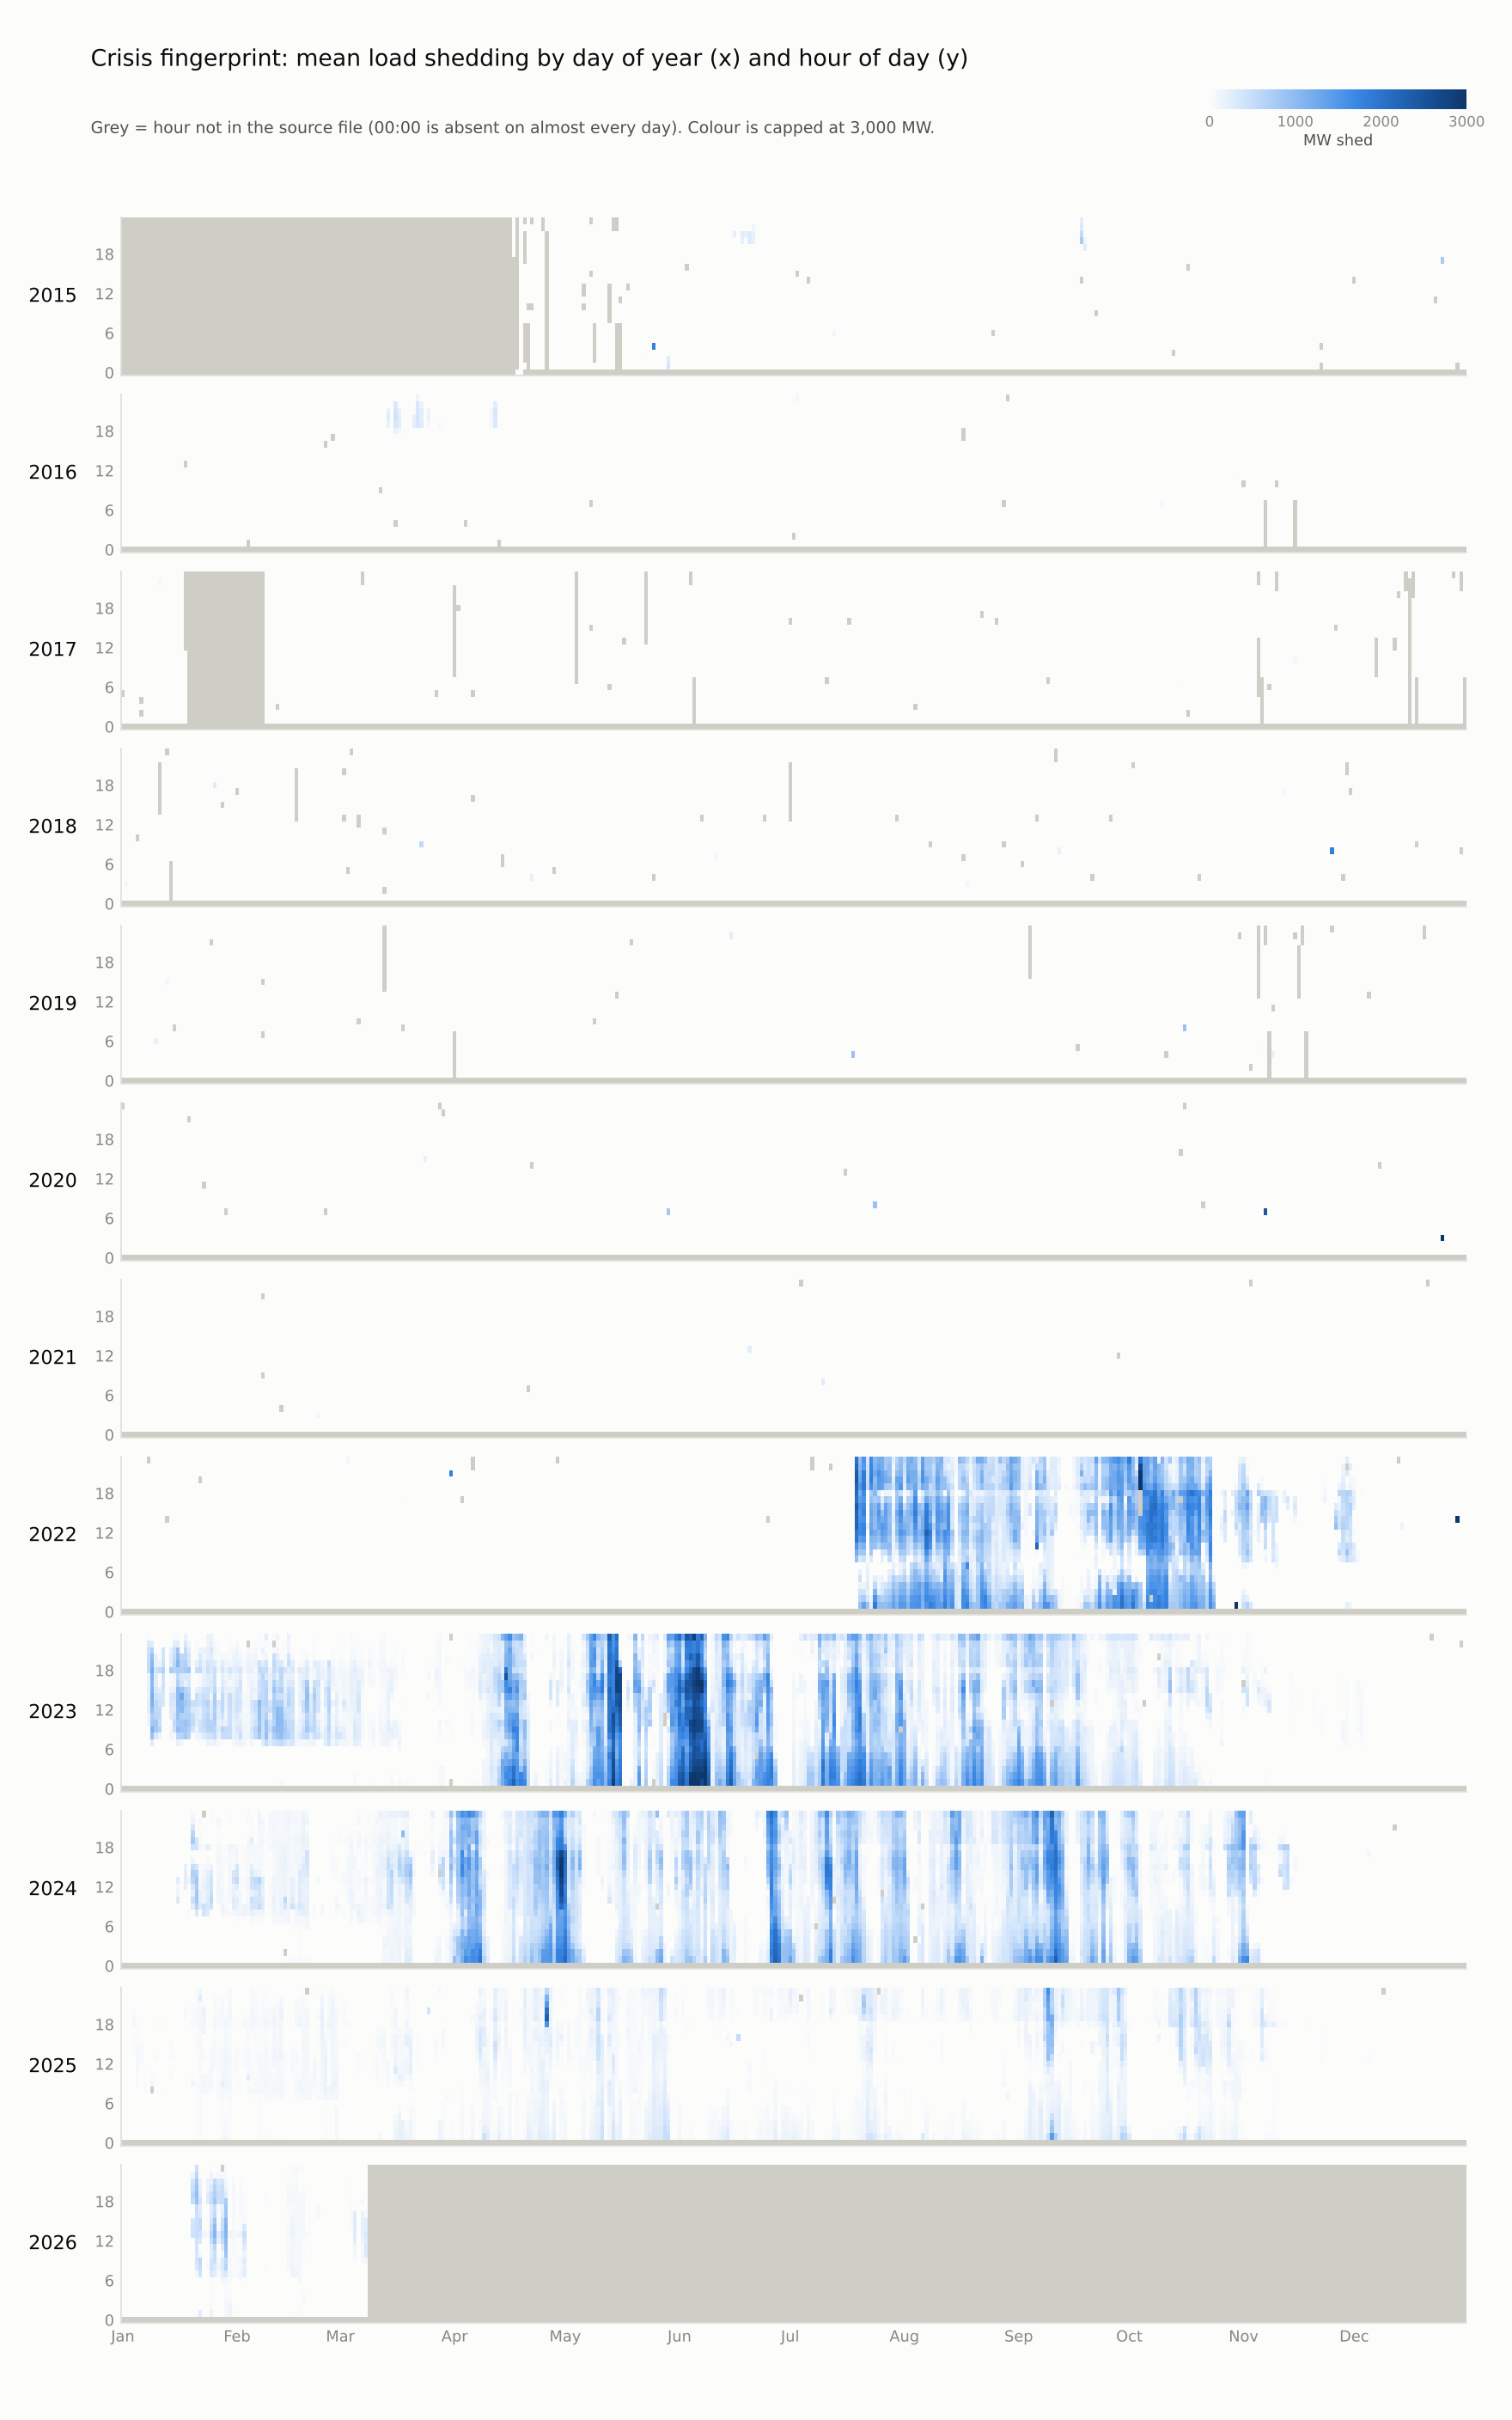

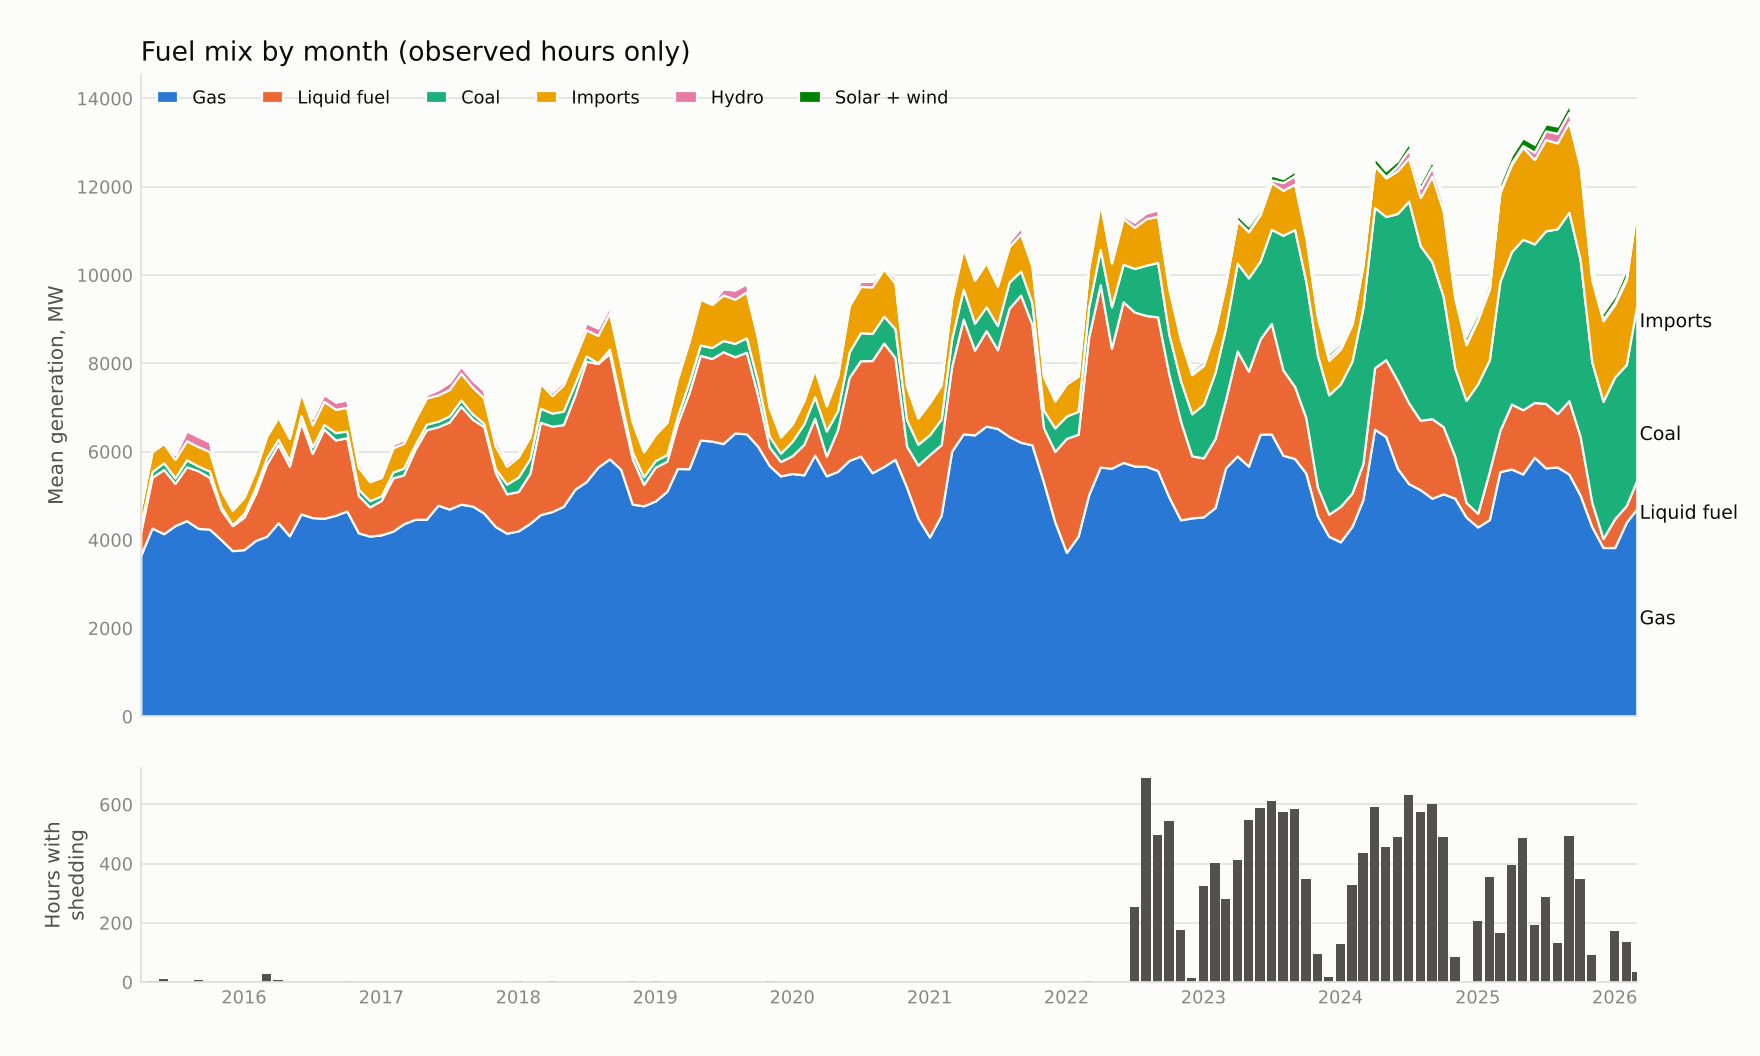

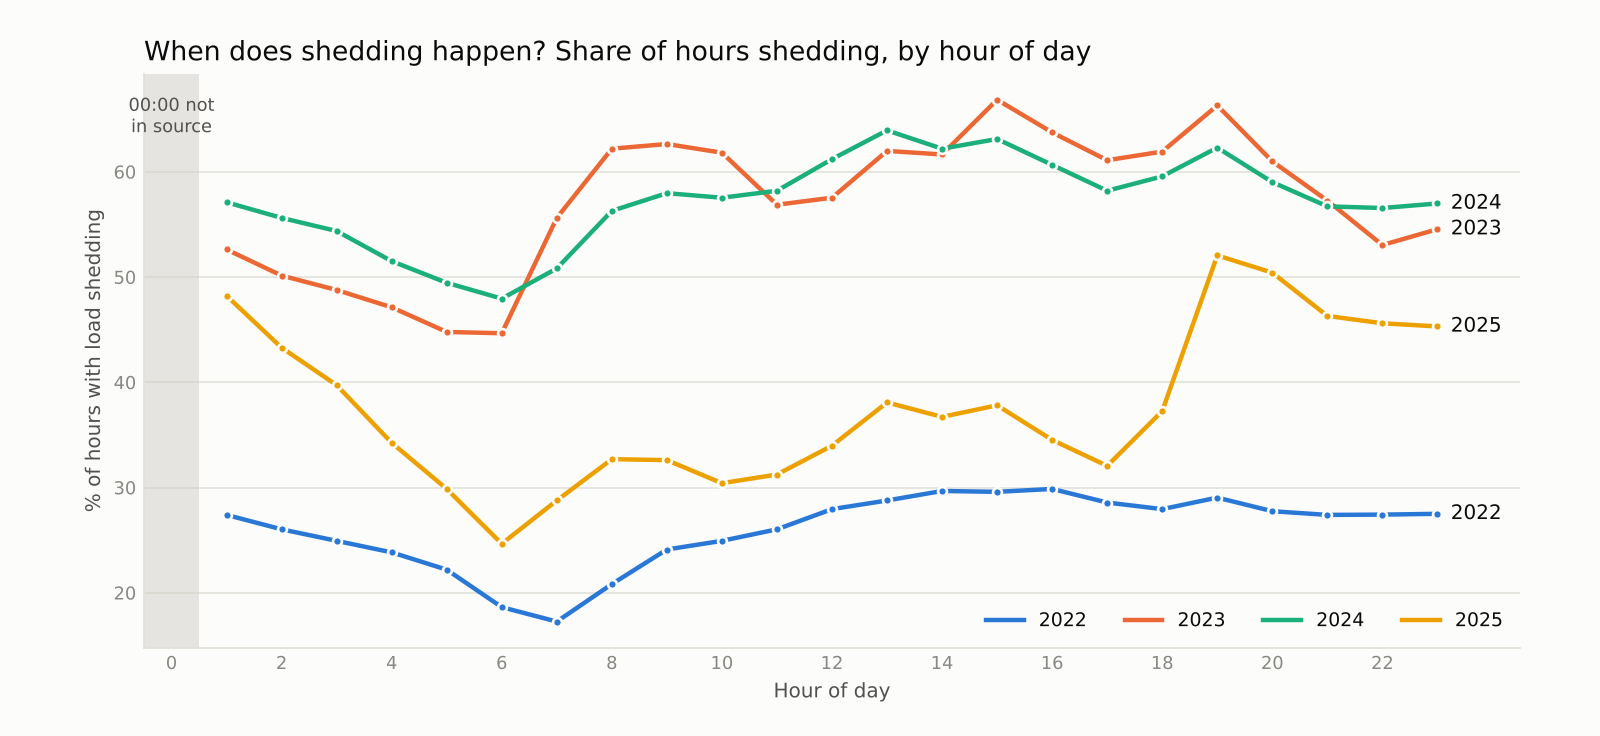

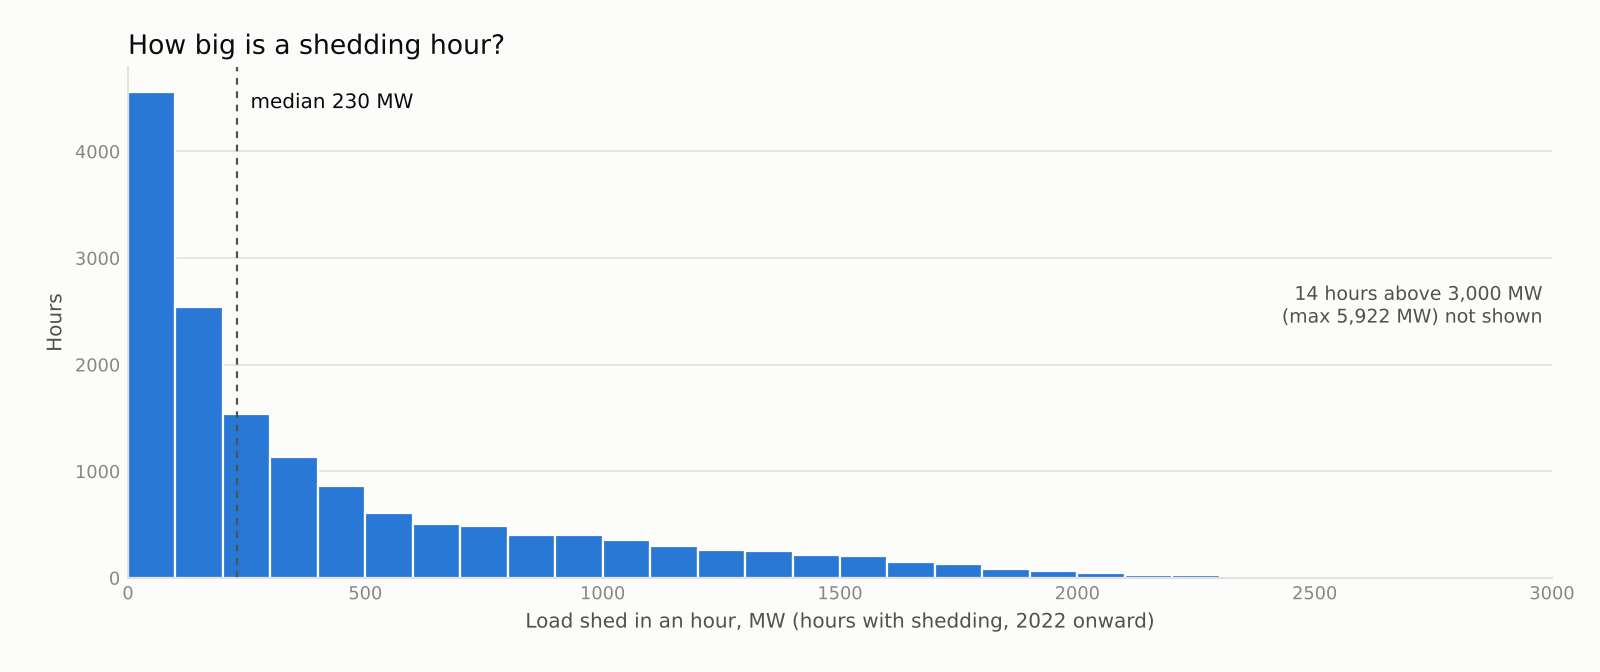

Share of hours with shedding, by hour of day
year        2022   2023   2024   2025
timestamp                            
1         27.400 52.600 57.100 48.200
2         26.000 50.100 55.600 43.300
3         24.900 48.800 54.400 39.700
4         23.800 47.100 51.500 34.200
5         22.200 44.800 49.500 29.900
6         18.600 44.700 47.900 24.700
7         17.300 55.600 50.800 28.800
8         20.800 62.200 56.300 32.700
9         24.100 62.600 58.000 32.600
10        24.900 61.800 57.500 30.400
11        26.000 56.900 58.200 31.200
12        27.900 57.500 61.200 34.000
13        28.800 62.000 63.900 38.100
14        29.700 61.600 62.200 36.700
15        29.600 66.800 63.100 37.800
16        29.900 63.700 60.700 34.500
17        28.600 61.100 58.200 32.100
18        27.900 61.900 59.600 37.300
19        29.000 66.300 62.300 52.100
20        27.700 61.000 59.000 50.400
21        27.400 57.300 56.700 46.300
22        27.400 53.000 56.600 45.600
23        27.500 54.500 57.000 45.300

Shar

In [19]:
config.DATA_INTERIM.mkdir(parents=True, exist_ok=True)
hourly.to_parquet(config.CLEAN_HOURLY_PATH)      # the later stages read this file
tables = eda.run()
for f in ["fingerprint", "fuel-mix", "hour-profile", "shedding-size"]:
    display(Image(filename=str(eda.FIG_DIR / f"{f}.png"), width=900))
print(tables[:1500])

### 3. Run every mining stage

In [20]:
R = mine.run(config.CLEAN_HOURLY_PATH, skip_cluster_search=not RUN_CLUSTER_SEARCH)
daily = R["daily"]

#### 3a. Regimes (PELT change points vs calendar split)

,signals,c,n_breaks,cost,calendar_cost,events_within_7d,breaks
0,shed+liquid+imports+coal+gas,0.500,41,"3,868.709","12,214.063",1,2015-05-13 2015-10-24 2016-02-28 2016-11-04 2017-01-22 2017-04-08 2017-10-14 2017-10-2...
1,shed+liquid+imports+coal+gas,1.000,29,"4,219.854","12,214.063",1,2015-10-24 2016-02-28 2016-11-04 2017-03-30 2017-10-14 2017-10-27 2018-03-04 2018-10-0...
2,shed+liquid+imports+coal+gas,2.000,17,"4,929.082","12,214.063",1,2016-02-28 2016-11-04 2017-03-28 2018-10-10 2019-03-13 2019-11-08 2020-05-10 2021-12-2...
3,shed+liquid+imports+coal+gas,4.000,12,"5,431.372","12,214.063",1,2016-02-28 2018-10-09 2019-11-09 2020-05-10 2021-12-27 2022-07-19 2022-11-11 2023-01-0...
4,shed+liquid+imports+coal+gas,8.000,5,"6,921.811","12,214.063",1,2018-10-10 2020-06-07 2022-07-19 2023-08-07 2024-08-28
5,shed+liquid+imports+coal+gas,16.000,4,"7,515.686","12,214.063",1,2020-06-07 2022-07-19 2023-08-07 2024-08-28
6,shed,0.500,34,577.836,"2,213.785",1,2022-07-19 2022-09-02 2022-09-20 2022-10-24 2022-11-11 2022-12-03 2023-01-08 2023-02-2...
7,shed,1.000,18,691.971,"2,213.785",1,2022-07-19 2022-10-24 2022-11-11 2023-01-08 2023-03-08 2023-04-08 2023-09-20 2023-10-2...
8,shed,2.000,13,745.684,"2,213.785",1,2022-07-19 2022-11-11 2023-01-08 2023-03-08 2023-04-08 2023-10-24 2024-01-18 2024-03-2...
9,shed,4.000,8,886.816,"2,213.785",1,2022-07-19 2022-11-11 2023-01-08 2023-10-24 2024-01-18 2024-11-05 2025-01-20 2025-11-11


best single break: {'multi': '2022-07-19', 'multi_cost': 11142.610177912538, 'calendar_cost': 12214.062713413712, 'shed_only': '2022-07-19', 'shed_only_cost': 1779.7527951703728, 'shed_only_calendar_cost': 2213.7845297442864}


,event,event_date,nearest_break,gap_days,within_7d
0,"Spot LNG purchases halted (mid-July 2022, approximate)",2022-07-15,2022-07-19,4,True
1,National grid failure (about half the country without power),2022-10-04,2022-07-19,-77,False


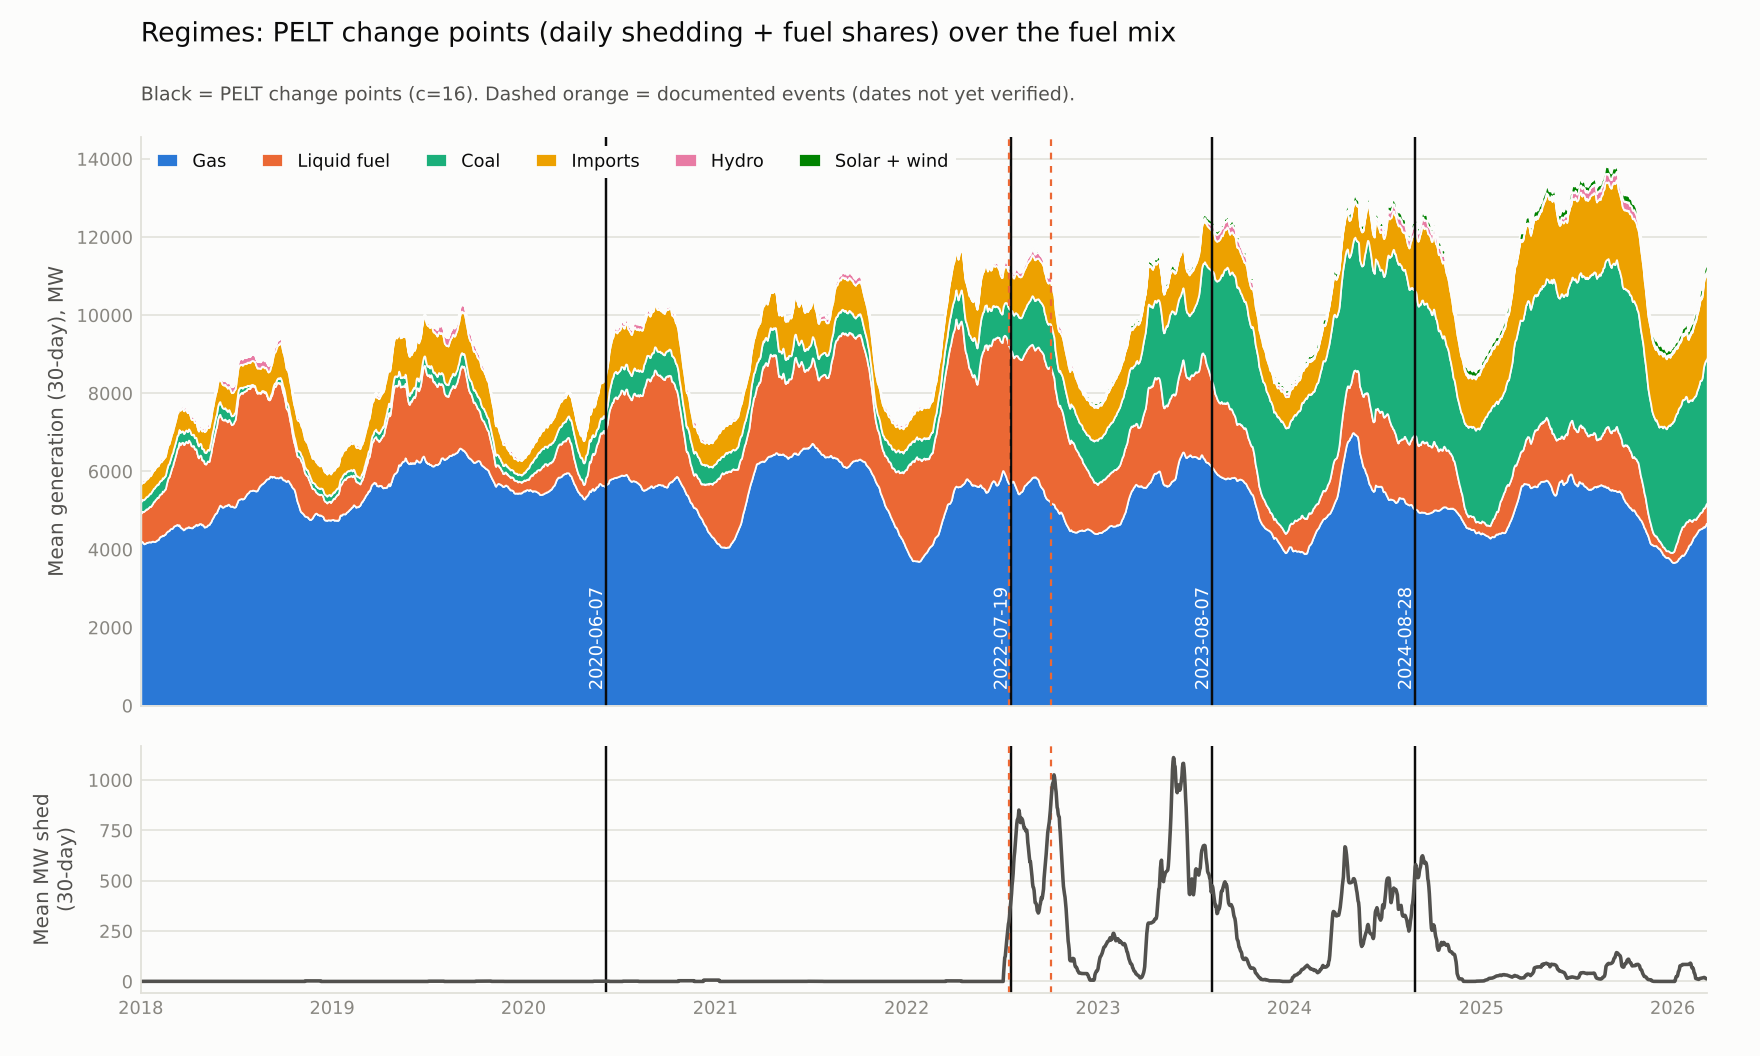

In [21]:
sweep = pd.read_csv(config.RESULTS / "regime_sweep.csv"); display(sweep[["signals", "c", "n_breaks", "cost", "calendar_cost", "events_within_7d", "breaks"]])
print("best single break:", R["regimes"]["best_single_break"])
display(pd.read_csv(config.RESULTS / "regime_event_alignment.csv"))
display(Image(filename=str(mine.FIG / "regimes.png"), width=900))

#### 3b. Archetype days (k-means vs DTW k-means vs k-Shape)

,method,k,silhouette,davies_bouldin,stability_ari,stability_reps,smallest_cluster
0,kmeans,2,0.650,0.729,0.994,4,192
1,kmeans,3,0.579,0.952,0.961,4,66
2,kmeans,4,0.447,1.176,0.735,4,54
3,kmeans,5,0.452,1.200,0.865,4,43
4,kshape,2,0.155,2.285,0.642,4,457
5,kshape,3,0.103,4.378,0.404,4,259
6,kshape,4,0.102,5.195,0.390,4,174
7,kshape,5,0.058,5.542,0.438,4,85
8,dtw,3,0.301,1.631,0.744,2,235
9,dtw,4,0.254,3.281,0.593,2,132


chosen: ('kmeans', 3) | days with usable profiles: {'days_total': 3958, 'days_dropped': 41, 'days_interpolated': 166}


,cluster,days,mean_mw_per_hour,peak_hour,peak_mw,night_share,year_mix
0,0,185,669.944,1,"1,167.908",0.379,"{""2022"": 0.31, ""2023"": 0.31, ""2024"": 0.36, ""2025"": 0.02, ""2026"": 0.01}"
1,1,727,104.776,1,162.743,0.308,"{""2022"": 0.06, ""2023"": 0.27, ""2024"": 0.27, ""2025"": 0.35, ""2026"": 0.04}"
2,2,66,"1,454.731",1,"1,820.333",0.310,"{""2022"": 0.3, ""2023"": 0.48, ""2024"": 0.21}"


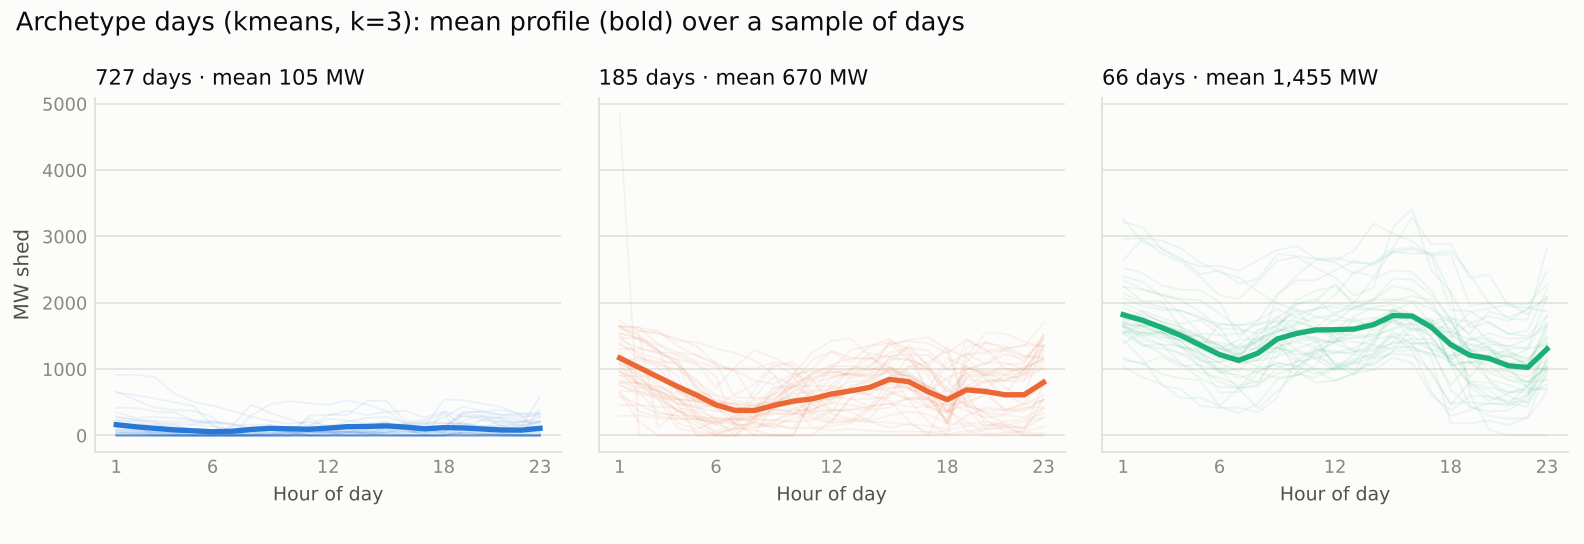

In [22]:
display(R["cluster_scores"].round(3))
print("chosen:", R["cluster_cfg"], "| days with usable profiles:", R["day_info"])
display(pd.read_csv(config.RESULTS / "cluster_archetypes.csv"))
display(Image(filename=str(mine.FIG / "archetypes.png"), width=900))

#### 3c. Motifs and discords (matrix profile)

,window_days,kind,start,end,neighbour_start,distance
0,7,motif,2023-01-04,2023-01-10,2026-01-16,0.103
1,7,motif,2023-10-06,2023-10-12,2023-05-29,0.178
2,7,motif,2025-07-21,2025-07-27,2023-10-01,0.180
3,7,discord,2022-07-31,2022-08-06,2023-02-16,1.507
4,7,discord,2022-09-26,2022-10-02,2023-02-23,1.439
5,7,discord,2023-09-12,2023-09-18,2024-09-18,1.370
6,7,discord,2023-01-27,2023-02-02,2023-02-06,1.341
7,7,discord,2024-06-02,2024-06-08,2023-01-25,1.280
8,14,motif,2022-07-08,2022-07-21,2026-01-09,0.397
9,14,motif,2022-12-30,2023-01-12,2022-07-10,0.578


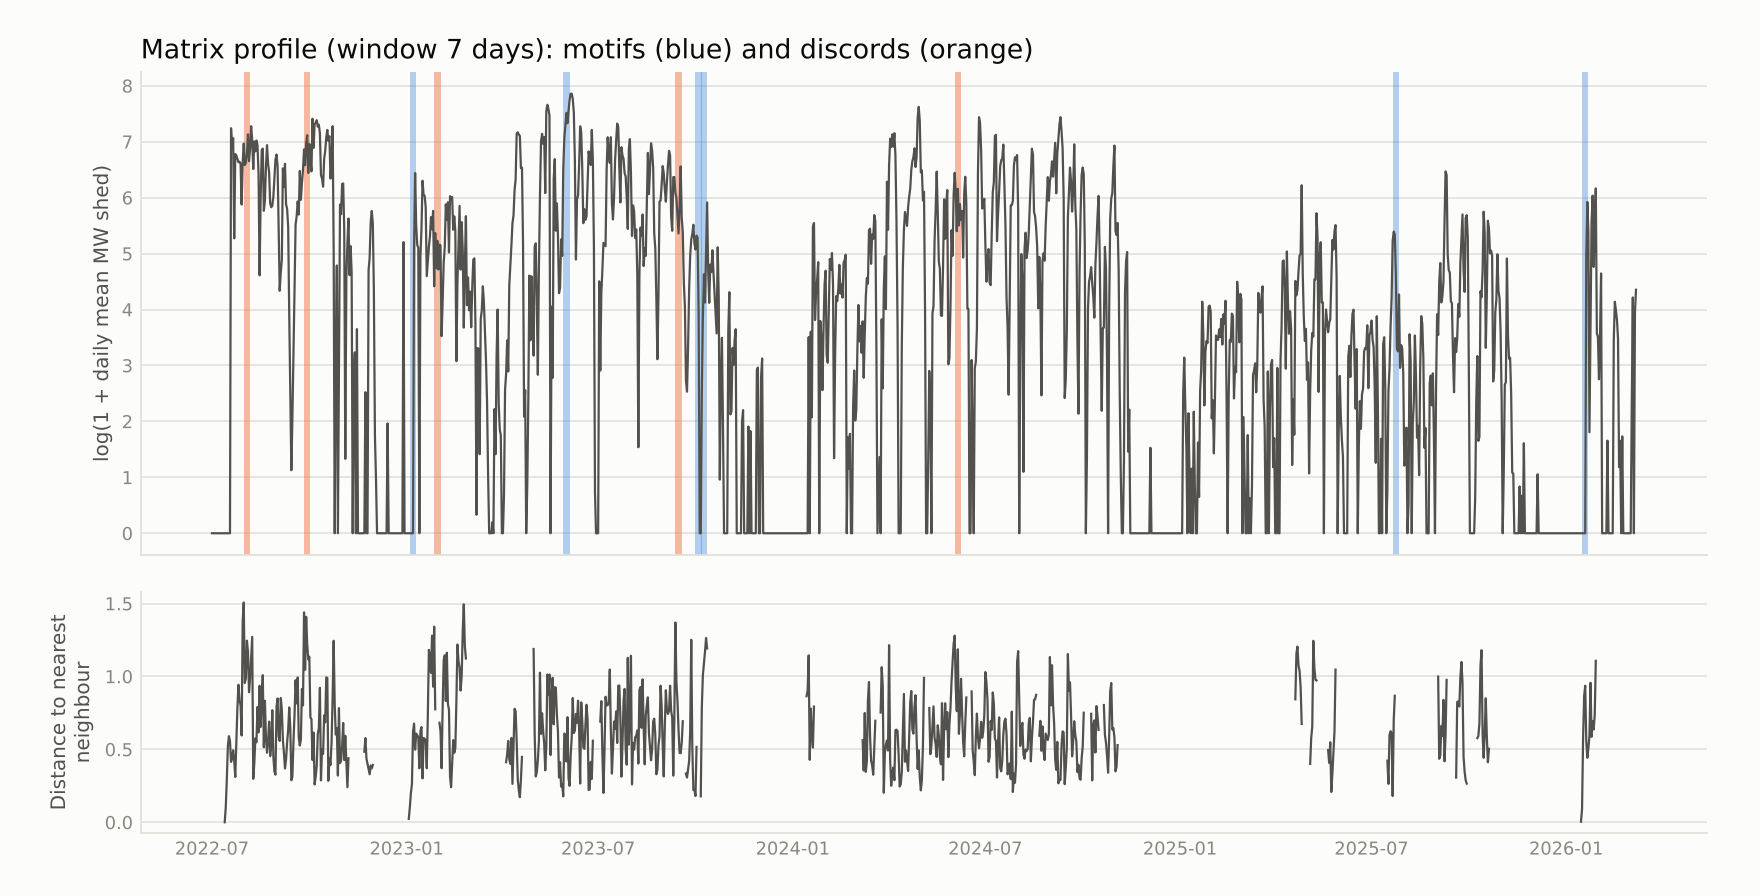

In [23]:
display(pd.read_csv(config.RESULTS / "matrix_profile_motifs_discords.csv"))
display(Image(filename=str(mine.FIG / "matrix-profile.png"), width=900))

#### 3d. Association rules and emerging patterns

Apriori baseline (all years): 64 rules in 4.6s | FP-Growth (crisis train): 397 rules in 0.23s
Baseline: top by confidence


,antecedent,support,confidence,lift,conviction,leverage,lift_vs_calendar
0,"day=weekday, gas=low, season=monsoon",0.011,0.271,5.254,1.300,0.009,2.523
1,"gas=low, imports=low",0.010,0.260,5.053,1.282,0.008,NaN
2,"gas=low, season=monsoon",0.012,0.241,4.681,1.250,0.010,2.605
3,"day=weekday, gas=mid, liquid_fuel=high",0.013,0.235,4.569,1.240,0.010,3.994
4,"gas=low, liquid_fuel=high",0.012,0.229,4.446,1.230,0.009,NaN
5,"gas=mid, season=monsoon",0.011,0.228,4.420,1.228,0.009,2.460
6,"coal=low, day=weekday, gas=mid",0.012,0.225,4.376,1.225,0.009,3.825
7,"day=weekday, gas=mid, imports=low",0.011,0.220,4.280,1.217,0.008,3.741


FP-Growth, crisis training period: top fuel-involving rules by lift


,antecedent,support,confidence,lift,conviction,leverage,lift_vs_calendar
0,"hour=night, liquid_fuel=high, season=monsoon",0.038,0.557,2.575,1.769,0.023,1.182
1,"coal=mid, hour=night, season=monsoon",0.015,0.549,2.538,1.737,0.009,1.165
2,"imports=mid, liquid_fuel=high, season=monsoon",0.026,0.533,2.463,1.677,0.015,1.465
3,"hour=afternoon, liquid_fuel=high, season=monsoon",0.028,0.532,2.459,1.674,0.017,1.385
4,"day=weekday, liquid_fuel=high, season=monsoon",0.082,0.530,2.449,1.666,0.049,1.251
5,"coal=low, hour=night, season=monsoon",0.028,0.526,2.433,1.654,0.016,1.117
6,"gas=mid, imports=mid, season=monsoon",0.012,0.520,2.405,1.633,0.007,1.431
7,"coal=low, gas=mid, season=monsoon",0.036,0.514,2.377,1.612,0.021,1.414
8,"gas=low, hour=night, season=monsoon",0.019,0.506,2.339,1.586,0.011,1.074
10,"coal=mid, gas=low, season=monsoon",0.023,0.503,2.327,1.577,0.013,1.384


Calendar-only rules (the 'obvious' ones)


,antecedent,support,confidence,lift,conviction,leverage,lift_vs_calendar
9,"day=weekday, hour=night, season=monsoon",0.040,0.504,2.330,1.580,0.023,NaN
24,"day=weekday, hour=afternoon, season=monsoon",0.032,0.475,2.197,1.493,0.018,NaN
27,"hour=night, season=monsoon",0.053,0.471,2.178,1.481,0.028,NaN
58,"day=weekday, season=monsoon",0.110,0.423,1.958,1.359,0.054,NaN
77,"day=weekday, hour=evening, season=monsoon",0.018,0.397,1.836,1.300,0.008,NaN


Emerging patterns, fuel mix only (none -> high shedding)


,pattern,n_items,support_high,support_none,growth_rate,calendar_only
0,"gas=low, imports=high, liquid_fuel=mid",3,0.043,0.005,8.719,False
1,"coal=mid, gas=low, imports=high",3,0.056,0.007,7.886,False
2,"gas=low, imports=high",2,0.066,0.010,6.954,False
3,"coal=low, gas=low, imports=low",3,0.053,0.009,5.999,False
4,"coal=low, gas=mid, imports=low",3,0.168,0.028,5.997,False
5,"coal=high, imports=low, liquid_fuel=high",3,0.059,0.010,5.902,False
6,"gas=low, imports=low, liquid_fuel=high",3,0.151,0.027,5.684,False
7,"coal=mid, gas=low, liquid_fuel=high",3,0.078,0.014,5.623,False
8,"coal=mid, gas=low, liquid_fuel=mid",3,0.040,0.007,5.575,False
9,"coal=mid, gas=low",2,0.118,0.021,5.493,False


Hold-out on 2025


,antecedent,train_lift,train_confidence,holdout_n,holdout_confidence,holdout_lift,holdout_base_rate
0,"hour=night, liquid_fuel=high, season=monsoon",2.575,0.557,170,0.088,10.427,0.008
1,"coal=mid, hour=night, season=monsoon",2.538,0.549,334,0.024,2.830,0.008
2,"imports=mid, liquid_fuel=high, season=monsoon",2.463,0.533,230,0.157,18.496,0.008
3,"hour=afternoon, liquid_fuel=high, season=monsoon",2.459,0.532,51,0.176,20.853,0.008
4,"day=weekday, liquid_fuel=high, season=monsoon",2.449,0.530,344,0.113,13.397,0.008
5,"coal=low, hour=night, season=monsoon",2.433,0.526,27,0.000,0.000,0.008
6,"gas=mid, imports=mid, season=monsoon",2.405,0.520,173,0.006,0.683,0.008
7,"coal=low, gas=mid, season=monsoon",2.377,0.514,0,NaN,NaN,0.008
8,"gas=low, hour=night, season=monsoon",2.339,0.506,640,0.023,2.770,0.008
9,"coal=mid, gas=low, season=monsoon",2.327,0.503,827,0.039,4.572,0.008


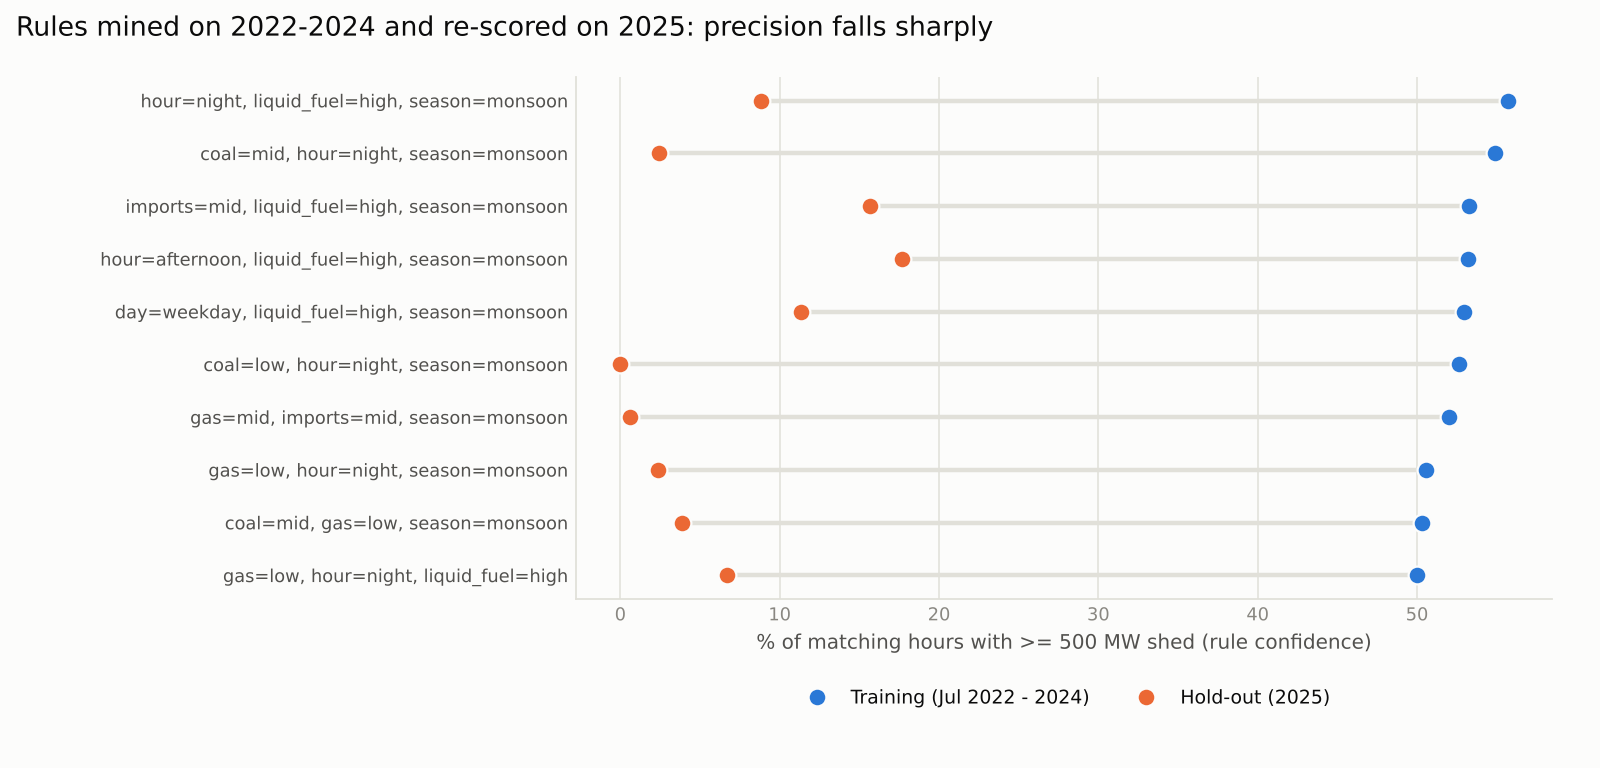

In [24]:
r = R["rules"]
print(f"Apriori baseline (all years): {len(r['base'])} rules in {r['base_s']:.1f}s | FP-Growth (crisis train): {len(r['crisis'])} rules in {r['fp_s']:.2f}s")
cols = ["antecedent", "support", "confidence", "lift", "conviction", "leverage", "lift_vs_calendar"]
print("Baseline: top by confidence"); display(r["base"].head(8)[cols].round(3))
print("FP-Growth, crisis training period: top fuel-involving rules by lift"); display(r["crisis"][~r["crisis"].calendar_only].head(10)[cols].round(3))
print("Calendar-only rules (the 'obvious' ones)"); display(r["crisis"][r["crisis"].calendar_only].head(5)[cols].round(3))
print("Emerging patterns, fuel mix only (none -> high shedding)"); display(r["ep_fuel"].head(10).round(3))
print("Hold-out on 2025"); display(r["hold"].round(3))
display(Image(filename=str(mine.FIG / "rules-holdout.png"), width=800))

#### 3e. Sequential patterns before shedding onsets (PrefixSpan)

In [25]:
e = R["episodes"]
display(e["patterns"].head(8).round(3))
print(f"best observed gap {e['best_gap']:.2f} | best-by-chance gap: median {e['null_gap_median']:.2f}, 95th percentile {e['null_gap_95']:.2f}")

,pattern,length,support_onset,support_control,gap,fisher_p,ratio,n_onsets,n_controls
0,gas_down -> liquid_up,2,0.320,0.160,0.160,0.100,2.000,50,50
1,imports_up -> liquid_down,2,0.300,0.140,0.160,0.090,2.143,50,50
2,coal_down -> gas_down -> liquid_up,3,0.200,0.060,0.140,0.071,3.333,50,50
3,imports_up -> coal_up,2,0.240,0.120,0.120,0.192,2.000,50,50
4,imports_up -> imports_down,2,0.240,0.120,0.120,0.192,2.000,50,50
5,gas_down -> coal_up,2,0.220,0.100,0.120,0.171,2.200,50,50
6,gas_down -> liquid_down -> liquid_up,3,0.180,0.060,0.120,0.121,3.000,50,50
7,gas_down -> imports_up -> coal_up,3,0.120,0.000,0.120,0.027,inf,50,50


best observed gap 0.16 | best-by-chance gap: median 0.18, 95th percentile 0.28


#### 3f. Anomalies

,detector,mean,std
0,iforest_1,0.885,0.039
1,iforest_all,0.090,0.046
2,zscore,0.872,0.036


rank of the 2022-10-04 grid failure among 2989 days: {'zscore': 37, 'iforest_1': 61, 'iforest_all': 120}
{'event_like': 48, 'data_error_like': 2}


,iforest_all,z_generation,z_shed,z_gas,z_coal,z_liquid,n_hours,flagged_bad_hours,tag
date,,,,,,,,,
2024-06-20,0.700,-29.600,-24.700,19.200,-18.200,-12.600,23.000,0,event_like
2022-10-25,0.700,-36.000,-85.800,10.300,9.600,-10.200,23.000,0,event_like
2024-06-19,0.700,-29.100,-16.500,17.400,-5.000,-13.900,23.000,0,event_like
2022-10-24,0.700,-28.900,-34.800,10.400,6.300,-12.400,23.000,0,event_like
2019-05-04,0.700,-39.400,-0.000,14.900,3.400,-16.900,23.000,0,event_like
2022-05-03,0.700,-26.300,0.300,14.100,0.300,-17.100,23.000,0,event_like
2026-02-12,0.700,-28.000,-3.700,12.000,-41.600,-1.000,23.000,0,event_like
2021-05-16,0.700,-29.000,0.000,11.900,1.600,-12.100,23.000,0,event_like
2019-06-05,0.700,-32.100,0.000,11.800,2.300,-11.200,23.000,0,event_like


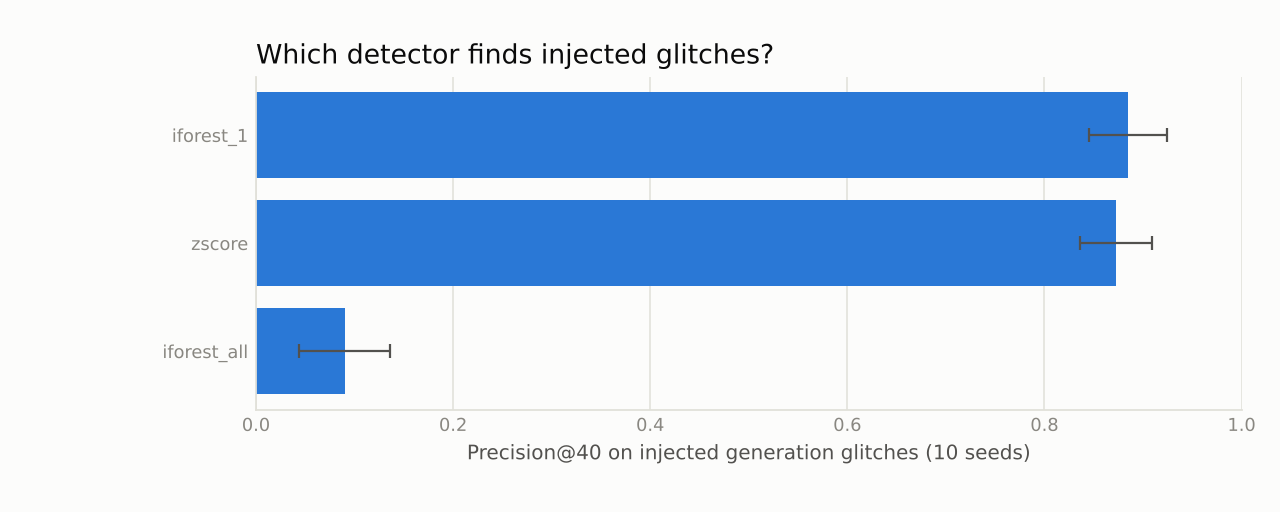

In [26]:
a = R["anomalies"]
display(a["bench"].round(3))
print("rank of the 2022-10-04 grid failure among", a["n_days"], "days:", a["grid_failure_rank"])
print(a["events"]["tag"].value_counts().to_dict())
display(a["events"].head(10).round(1))
display(Image(filename=str(mine.FIG / "anomaly-benchmark.png"), width=600))

### 4. Models and algorithms used

In [27]:
import importlib.metadata as md_
def v(p):
    try: return md_.version(p)
    except Exception: return "n/a"
models = pd.DataFrame([
    ("Change points", "PELT (l2 cost, min segment 14 d, jump 5 d + exact-day refinement)", f"ruptures {v('ruptures')}", "daily shedding + fuel shares"),
    ("Change points (baseline)", "calendar split 2022-01-01; best single break (exhaustive)", "numpy", "same"),
    ("Archetype days (baseline)", "k-means on raw MW", f"scikit-learn {v('scikit-learn')}", "978 crisis days x 23 h"),
    ("Archetype days", "DTW k-means (TimeSeriesKMeans)", f"tslearn {v('tslearn')}", "z-normalised profiles"),
    ("Archetype days", "k-Shape", f"tslearn {v('tslearn')}", "z-normalised profiles"),
    ("Cluster evaluation", "silhouette, Davies-Bouldin, bootstrap ARI", f"scikit-learn {v('scikit-learn')}", ""),
    ("Motifs and discords", "matrix profile (stump), windows 7 and 14 days", f"stumpy {v('stumpy')}", "log daily MW shed"),
    ("Rules (baseline)", "Apriori, ranked by confidence", f"mlxtend {v('mlxtend')}", "hourly discretised states, all years"),
    ("Rules", "FP-Growth + lift / conviction / leverage / lift-vs-calendar", f"mlxtend {v('mlxtend')}", "crisis training period"),
    ("Emerging patterns", "support growth none -> high shedding (Dong & Li)", f"mlxtend {v('mlxtend')}", "crisis training period"),
    ("Episodes", "PrefixSpan (own implementation) + Fisher exact + permutation null", f"scipy {v('scipy')}", "3 days before shedding onsets"),
    ("Anomalies (baseline)", "robust z-score of the STL residual", f"statsmodels {v('statsmodels')}", "daily generation"),
    ("Anomalies", "Isolation Forest on STL residuals (1 feature and 5 features)", f"scikit-learn {v('scikit-learn')}, statsmodels {v('statsmodels')}", "daily residuals"),
], columns=["task", "method", "library", "data"])
display(models)

,task,method,library,data
0,Change points,"PELT (l2 cost, min segment 14 d, jump 5 d + exact-day refinement)",ruptures 1.1.10,daily shedding + fuel shares
1,Change points (baseline),calendar split 2022-01-01; best single break (exhaustive),numpy,same
2,Archetype days (baseline),k-means on raw MW,scikit-learn 1.9.1,978 crisis days x 23 h
3,Archetype days,DTW k-means (TimeSeriesKMeans),tslearn 0.10.0,z-normalised profiles
4,Archetype days,k-Shape,tslearn 0.10.0,z-normalised profiles
5,Cluster evaluation,"silhouette, Davies-Bouldin, bootstrap ARI",scikit-learn 1.9.1,
6,Motifs and discords,"matrix profile (stump), windows 7 and 14 days",stumpy 1.14.1,log daily MW shed
7,Rules (baseline),"Apriori, ranked by confidence",mlxtend 0.25.0,"hourly discretised states, all years"
8,Rules,FP-Growth + lift / conviction / leverage / lift-vs-calendar,mlxtend 0.25.0,crisis training period
9,Emerging patterns,support growth none -> high shedding (Dong & Li),mlxtend 0.25.0,crisis training period
